# Packages

In [ ]:
import polars as pl
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
import shap
import warnings
warnings.filterwarnings('ignore')


from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from catboost import CatBoostClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from matplotlib.colors import ListedColormap
from sklearn.metrics import precision_recall_curve
from sklearn.tree import plot_tree
from sklearn.model_selection import TunedThresholdClassifierCV
from sklearn.model_selection import RandomizedSearchCV
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier

# Downloading Data

The synthetic dataset `loan_portfolio` is available from [the link](https://www.kaggle.com/datasets/sergionefedov/credit-risk-dataset-50k-loans-10-sectors). The datset has the following original columns:


| Variable | Description |
|---|---|
| `loan_id` | Unique loan identifier |
| `origination_date` | Loan origination date |
| `maturity_date` | Scheduled maturity date |
| `maturity_months` | Tenor in months (12–120) |
| `sector` | Borrower industry sector (10 sectors) |
| `loan_type` | term_loan / revolving / mortgage / bond / lease |
| `collateral` | secured / unsecured / partially_secured |
| `initial_rating` | Credit rating at origination (AAA–CCC) |
| `credit_score` | Borrower credit score (300–850) |
| `ead` | Exposure at Default — outstanding balance ($) |
| `coupon_rate` | Loan interest rate (%) |
| `leverage` | Debt / EBITDA ratio |
| `interest_coverage` | EBIT / Interest expense |
| `debt_to_equity` | D/E ratio |
| `pd_annual` | Probability of Default (annual, Basel IRB approach) |
| `lgd` | Loss Given Default (0–1; accounts for collateral) |
| `el` | Expected Loss = PD × LGD × EAD ($) |
| `unexpected_loss` | Unexpected Loss = √(PD × (1 − PD)) × LGD × EAD ($) |
| `rwa` | Risk-Weighted Assets (simplified Basel formula, $) |
| `defaulted` | Binary: 1 if loan defaulted during its life |
| `default_date` | Date of default (null if no default) |
| `survival_months` | Months until default or maturity |
| `recovery_rate` | 1 − LGD (for defaulted loans) |
| `loss_given_default` | Actual loss = LGD × EAD (for defaulted loans, $) |

In [8]:
df = pl.read_csv("data/loan_portfolio.csv")
df.head()

loan_id,origination_date,maturity_date,maturity_months,sector,loan_type,collateral,initial_rating,credit_score,ead,coupon_rate,leverage,interest_coverage,debt_to_equity,pd_annual,lgd,el,unexpected_loss,rwa,defaulted,default_date,survival_months,recovery_rate,loss_given_default
str,str,str,i64,str,str,str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,str,i64,f64,f64
"""L000001""","""2017-10-01""","""2019-10-01""",24,"""Technology""","""mortgage""","""secured""","""B""",704,1.0356e6,3.776,6.54,3.47,1.4,0.041076,0.7858,33426.8,161508.03,442905.14,0,null,24,null,null
"""L000002""","""2016-06-01""","""2020-06-01""",48,"""Healthcare""","""term_loan""","""unsecured""","""A""",702,800786.92,3.895,12.26,4.47,2.77,0.000887,0.7034,499.82,16771.62,6622.66,0,null,48,null,null
"""L000003""","""2023-08-01""","""2024-12-31""",36,"""Real_Estate""","""bond""","""secured""","""BBB""",699,4.3279e6,4.365,8.98,6.02,2.18,0.002622,0.5503,6243.54,121781.72,82726.94,0,null,36,null,null
"""L000004""","""2016-04-01""","""2024-12-31""",120,"""Real_Estate""","""term_loan""","""secured""","""B""",641,3.8105e6,3.749,13.12,5.93,1.75,0.041679,0.3541,56237.33,269661.85,745144.64,0,null,120,null,null
"""L000005""","""2015-10-01""","""2019-10-01""",48,"""Energy""","""bond""","""unsecured""","""CCC""",597,2.9255e6,5.231,1.8,4.39,1.79,0.136071,0.6576,261778.69,659614.05,3.4686e6,0,null,48,null,null


Some columns may cause data leakage or be irrelevant for the algorithms, namely `default_date`, `survival_months`, `recovery_rate`, `loss_given_default` are calculated for defaulted loans, `pd_annual`, `lgd`, `el` and `unexpected_loss`, `rwa` present in datsset for calculating Basel risk metrics, in this project we do not focus on them. The corresponding columns are to be dropped:

In [9]:
columns_to_drop = [
    'loan_id', 
    "maturity_date", 
    "default_date", 
    "survival_months", 
    "recovery_rate", 
    "loss_given_default", 
    'ead', 'pd_annual', 
    'lgd', 
    'el', 
    'unexpected_loss', 
    'rwa'
]
df = df.select(pl.exclude(columns_to_drop))

It will be useful later to keep the lists by column types while plotting and encoding columns.

In [6]:
num = ['credit_score', 'coupon_rate', 'leverage', 'interest_coverage', 'debt_to_equity', 'defaulted']
cats = ['origination_date', 'maturity_months', 'sector', 'loan_type', 'collateral', 'initial_rating']
target = 'defaulted'

# Initial exploration

In [8]:
df[target].value_counts(normalize=True)

defaulted,proportion
i64,f64
1,0.139
0,0.861


The target variable classes are unbalanced

In [247]:
print(f"Initial DataFrame shape: {df.shape}")
print(f"Double counts: {sum(df.is_duplicated())}")


Initial DataFrame shape: (50000, 11)
Double counts: 0


In [192]:
df.select(cats).approx_n_unique()

maturity_months,sector,loan_type,collateral,initial_rating
u32,u32,u32,u32,u32
7,10,5,3,7


Descriptive statistics of numerical columns:

In [9]:
df.select(pl.exclude(['origination_date','sector', 'loan_type', 'collateral', 'initial_rating'])).describe()

statistic,maturity_months,credit_score,coupon_rate,leverage,interest_coverage,debt_to_equity,defaulted
str,f64,f64,f64,f64,f64,f64,f64
"""count""",50000.0,50000.0,50000.0,50000.0,50000.0,50000.0,50000.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",53.97048,714.98256,3.079087,6.9137786,3.764089,2.090884,0.139
"""std""",26.716251,50.893411,1.103558,3.686415,2.014019,1.570126,0.34595
"""min""",12.0,518.0,1.0,0.5,0.5,0.1,0.0
"""25%""",36.0,679.0,2.357,4.06,2.37,1.03,0.0
"""50%""",48.0,715.0,3.064,6.08,3.31,1.65,0.0
"""75%""",60.0,750.0,3.735,9.07,4.65,2.64,0.0
"""max""",120.0,850.0,7.531,15.0,20.0,10.0,1.0


The share of defaulted borrowers is uniform across sectors:

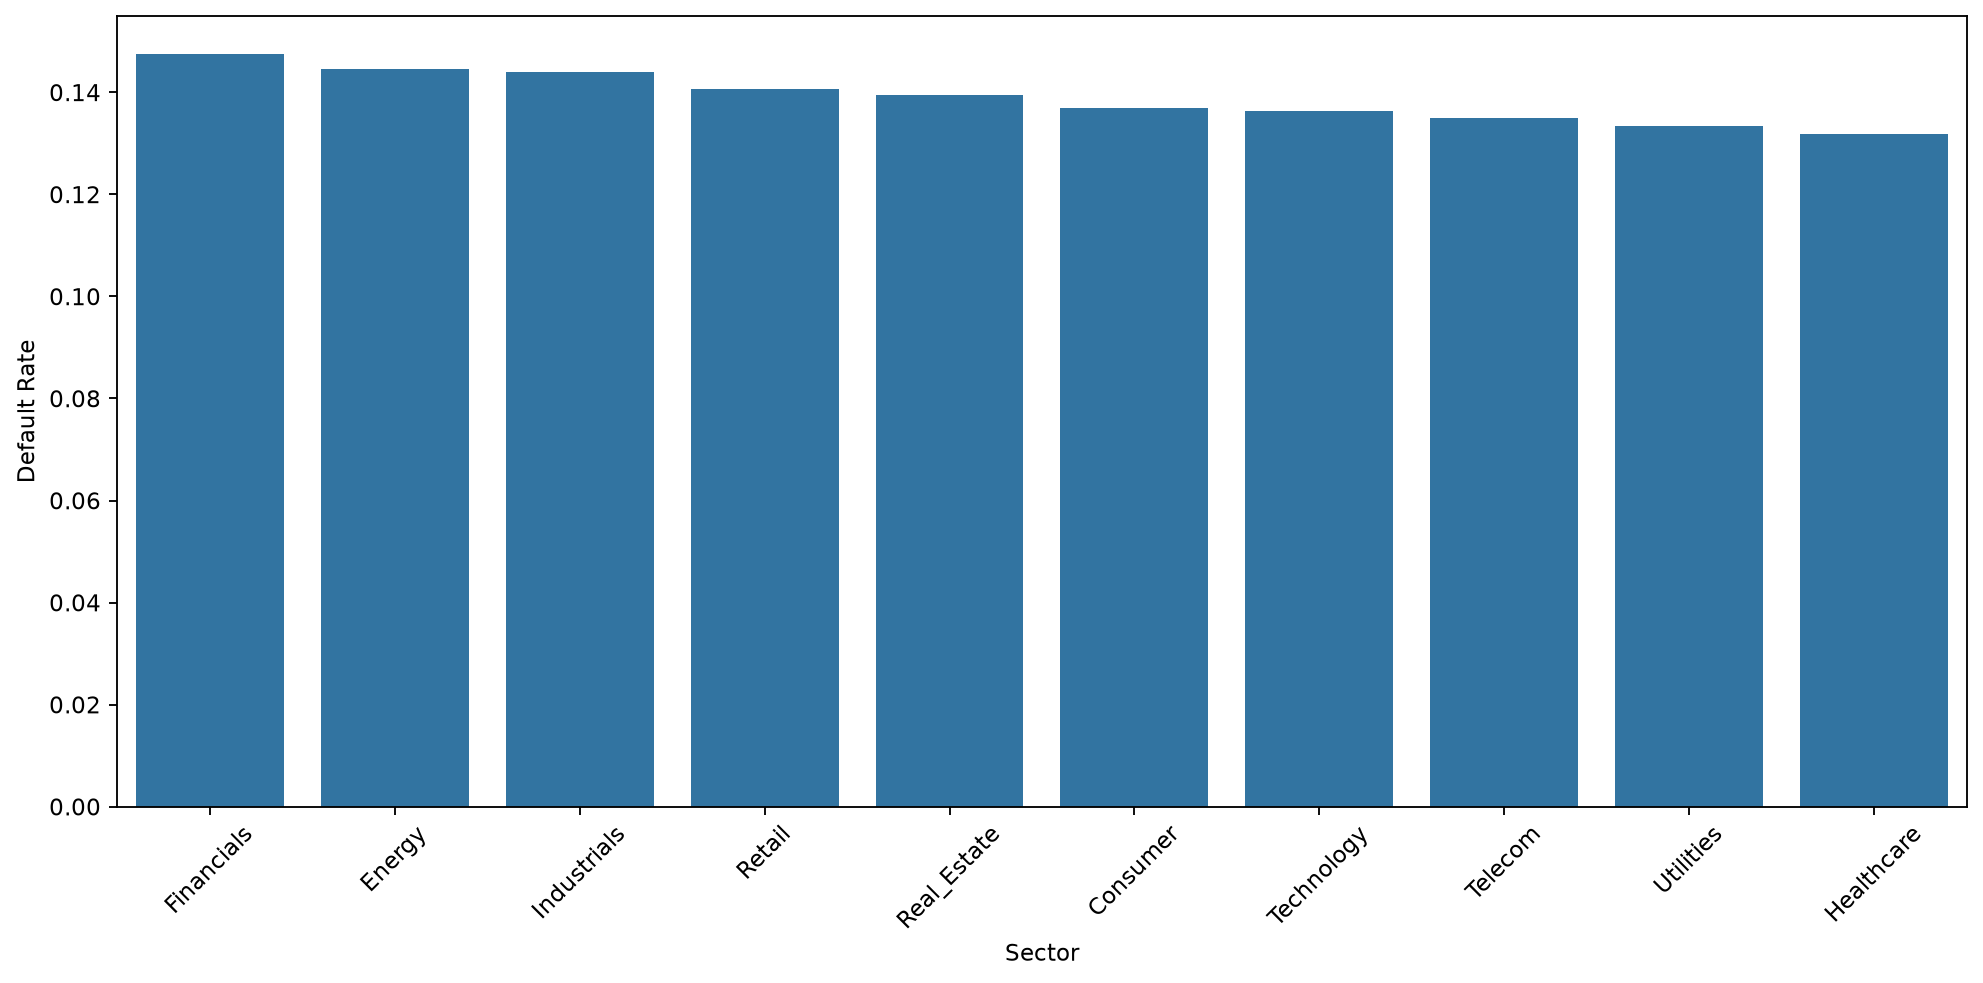

In [ ]:
sector_rate = (df
    .group_by('sector')
    .agg(pl.col('defaulted').mean().alias('default_rate'))
    .sort('default_rate', descending=True)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=sector_rate,
    x='sector',
    y='default_rate'
)

plt.xlabel('Sector')
plt.ylabel('Default Rate')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Numerical variables are mostly skewed to the left and have heavy right tails.

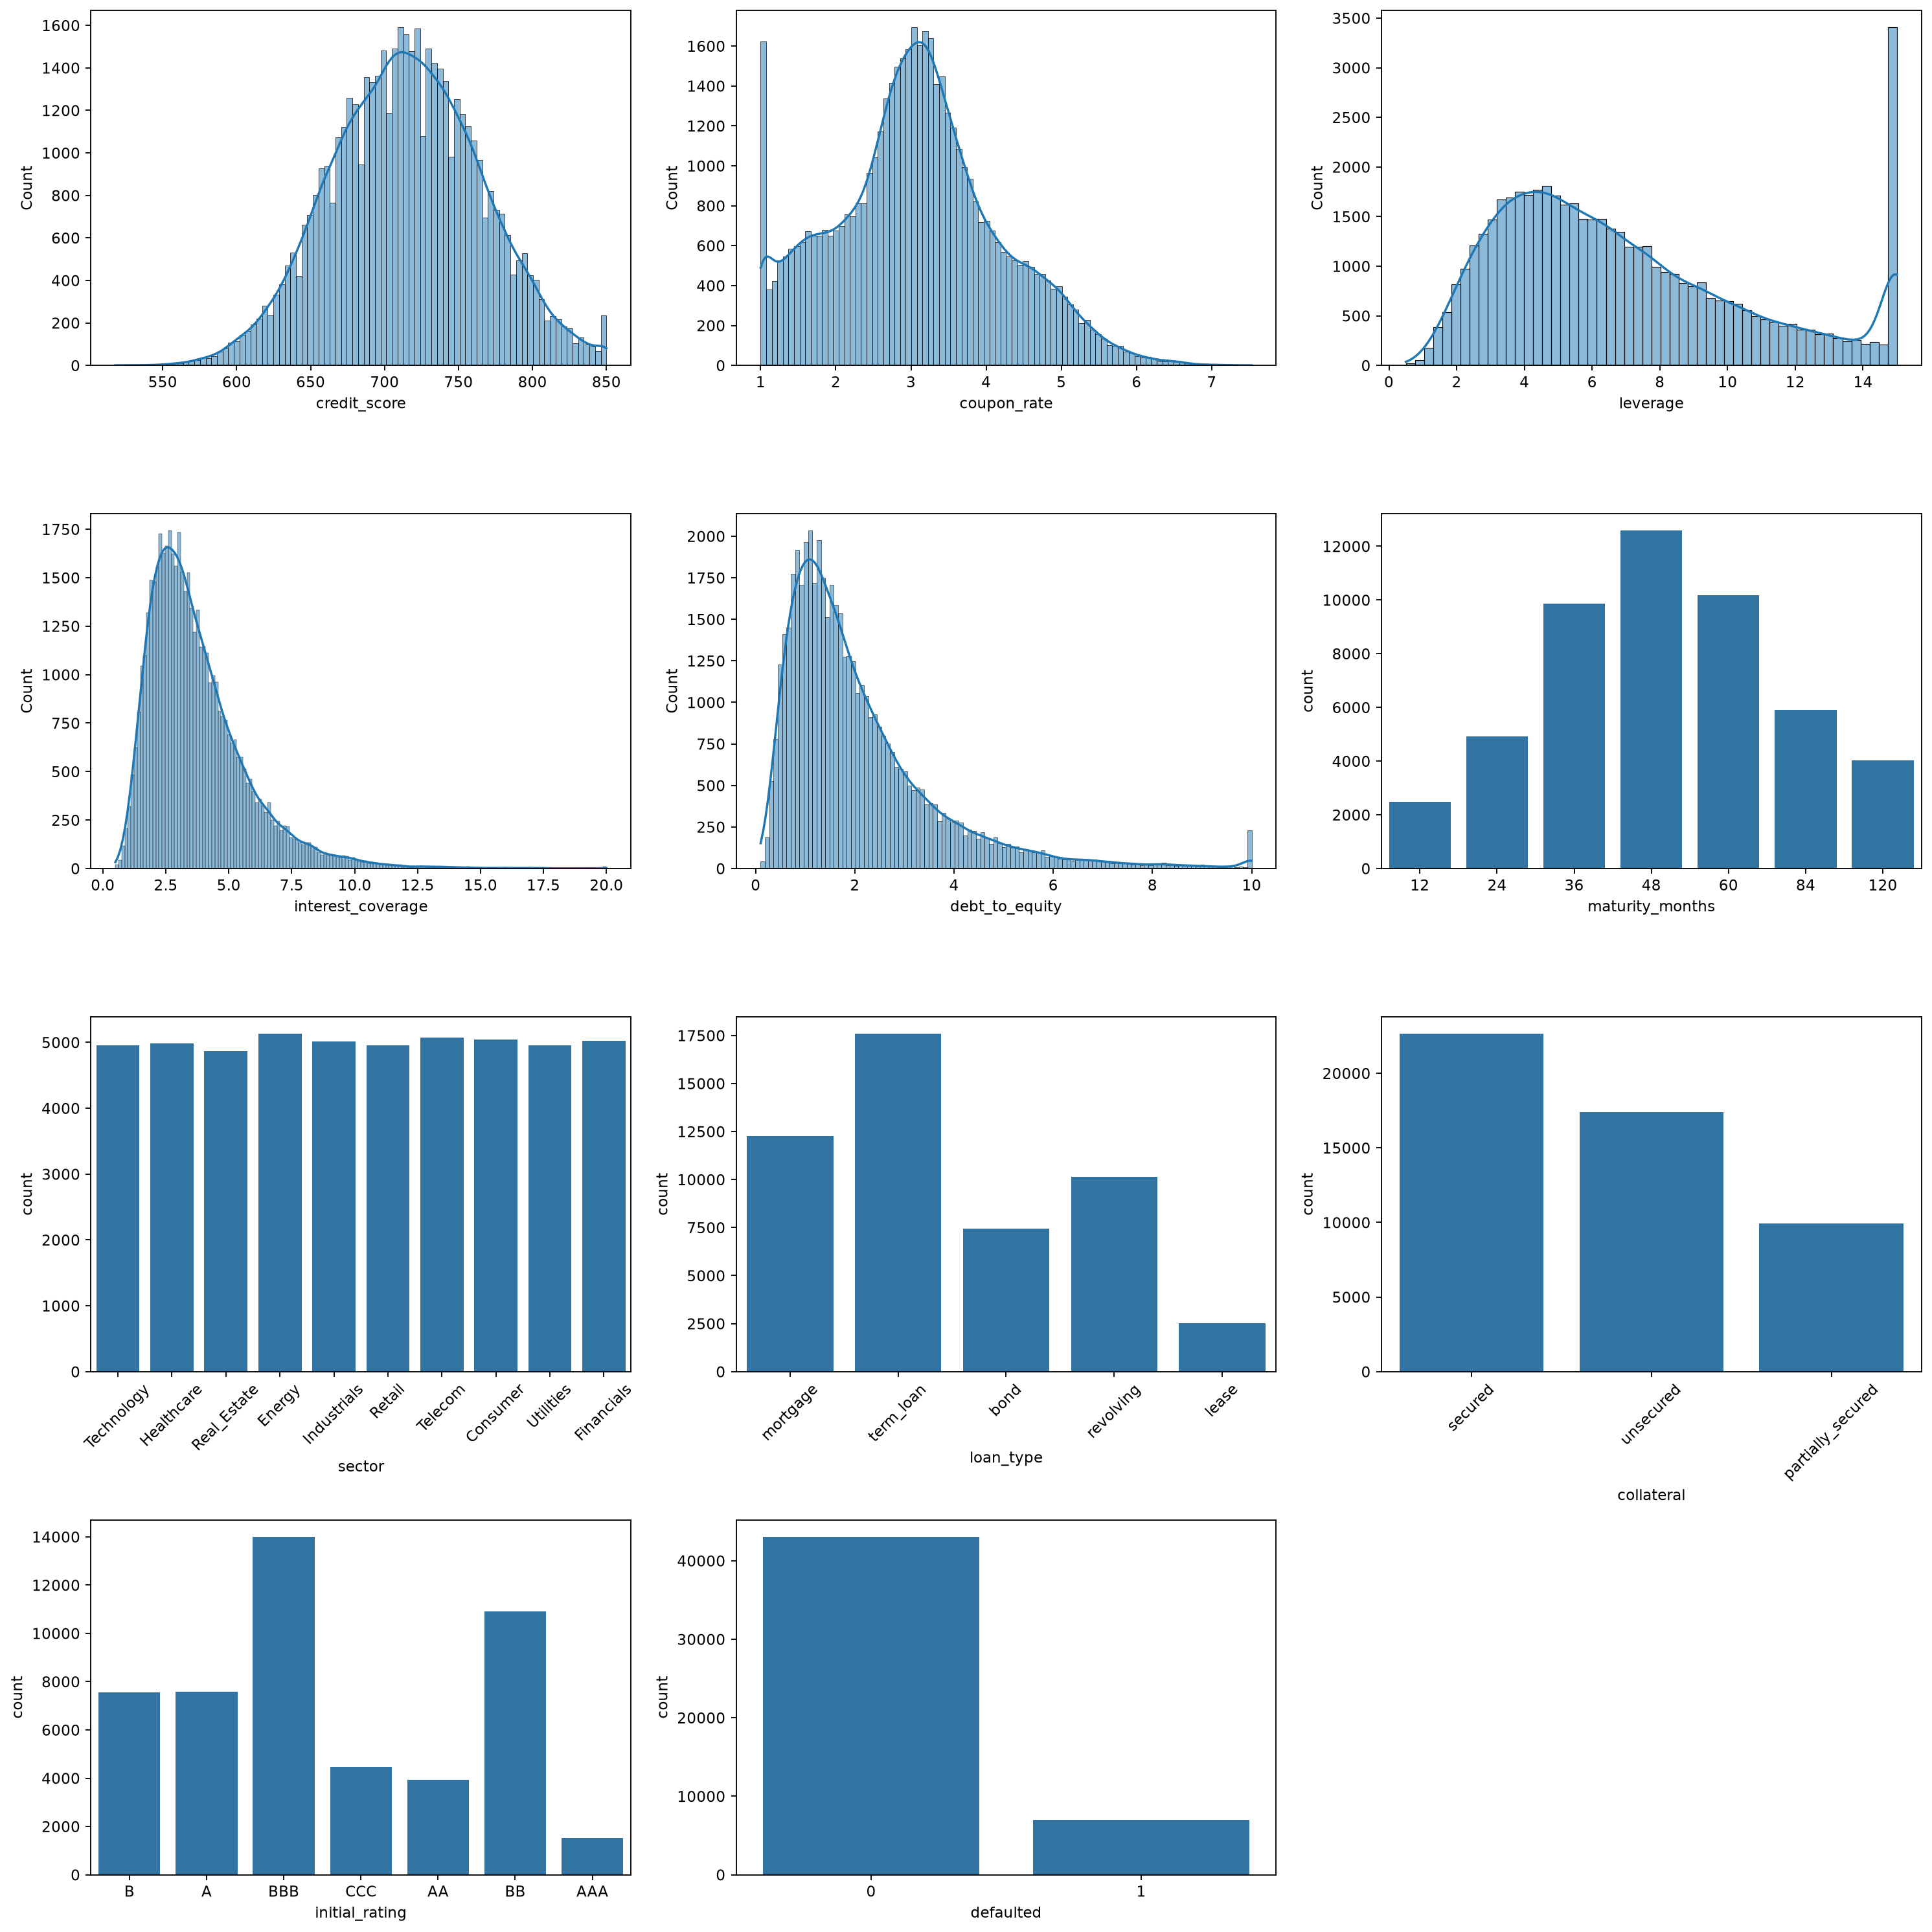

In [97]:
fig, axes = plt.subplots(4, 3, figsize=(18, 18))

# Numerical
sns.histplot(data=df, x='credit_score', kde=True, ax=axes[0, 0])
sns.histplot(data=df, x='coupon_rate', kde=True, ax=axes[0, 1])
sns.histplot(data=df, x='leverage', kde=True, ax=axes[0, 2])

sns.histplot(data=df, x='interest_coverage', kde=True, ax=axes[1, 0])
sns.histplot(data=df, x='debt_to_equity', kde=True, ax=axes[1, 1])

# Categorical
sns.countplot(data=df, x='maturity_months', ax=axes[1, 2])
sns.countplot(data=df, x='sector', ax=axes[2, 0])
sns.countplot(data=df, x='loan_type', ax=axes[2, 1])

sns.countplot(data=df, x='collateral', ax=axes[2, 2])
sns.countplot(data=df, x='initial_rating', ax=axes[3, 0])
sns.countplot(data=df, x='defaulted', ax=axes[3, 1])

# Empty 12th subplot
axes[3, 2].axis('off')

axes[2, 0].tick_params(axis='x', rotation=45)
axes[2, 1].tick_params(axis='x', rotation=45)
axes[2, 2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

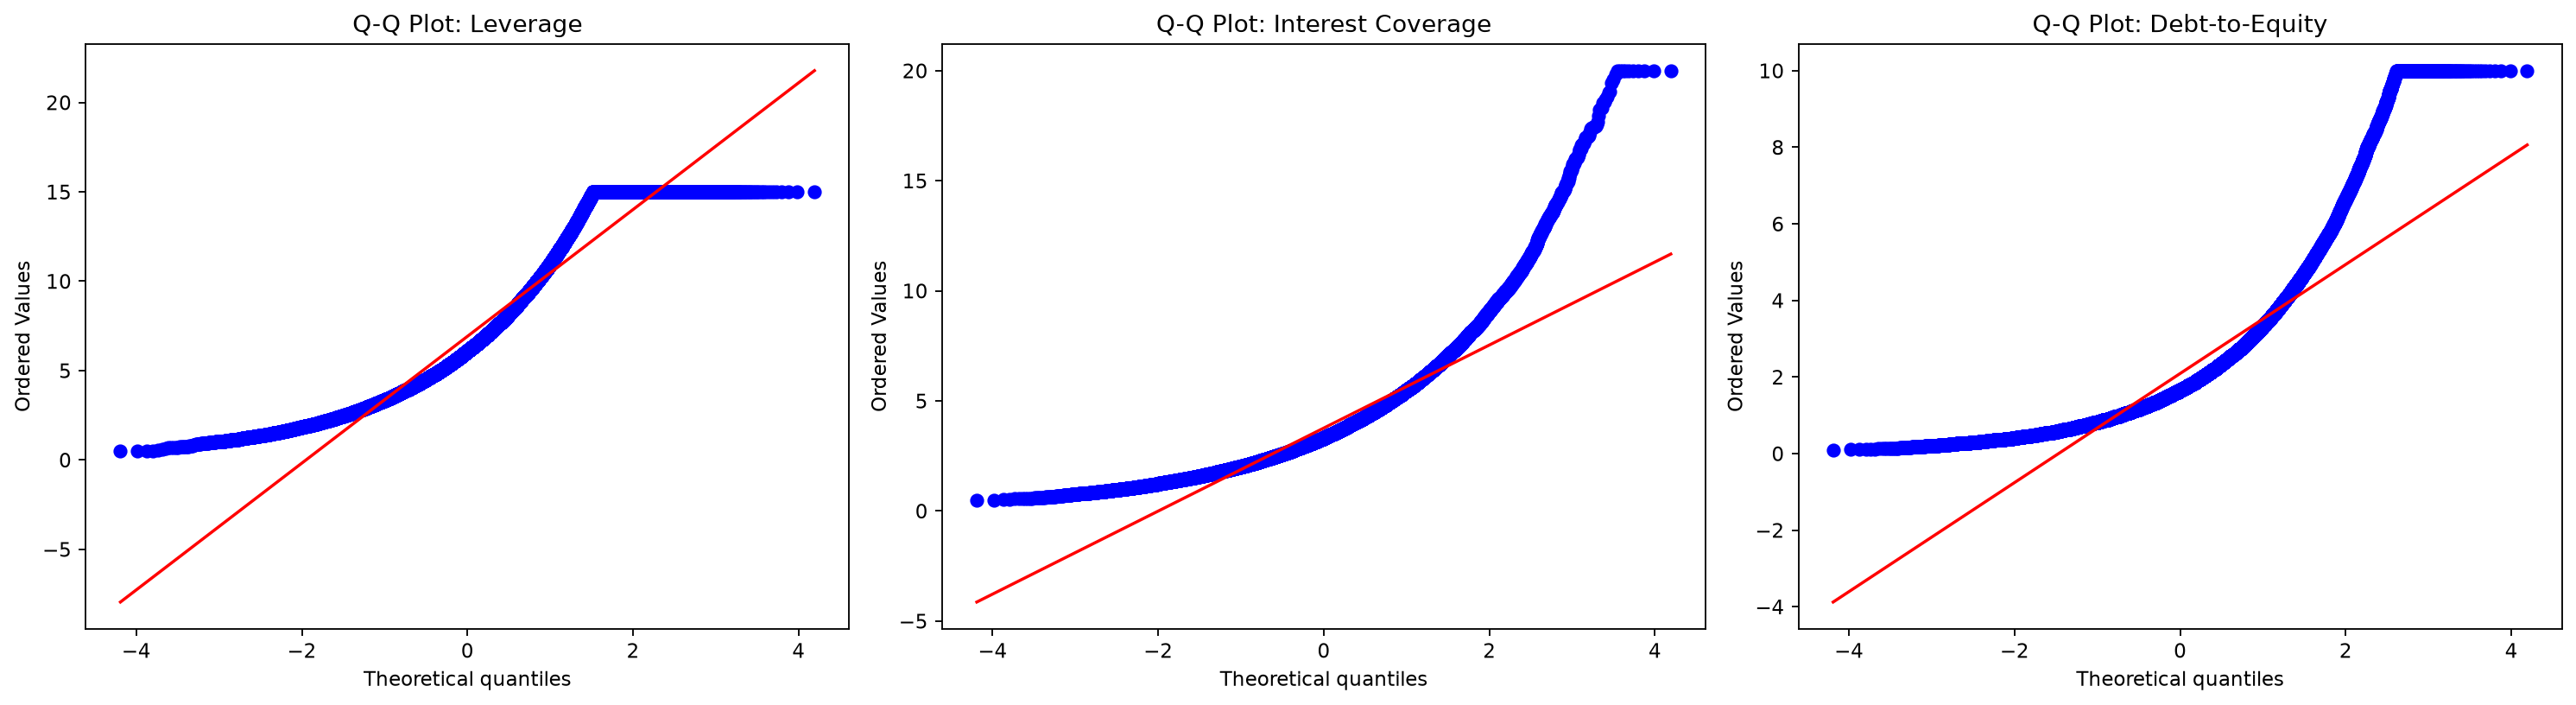

In [130]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

stats.probplot(df['leverage'], dist='norm', plot=axes[0])
axes[0].set_title('Q-Q Plot: Leverage')

stats.probplot(df['interest_coverage'], dist='norm', plot=axes[1])
axes[1].set_title('Q-Q Plot: Interest Coverage')

stats.probplot(df['debt_to_equity'], dist='norm', plot=axes[2])
axes[2].set_title('Q-Q Plot: Debt-to-Equity')

plt.tight_layout()
plt.show()

Leverage, Interest Coverage and DE-ratio variables differ from Normal distribution based on QQ-plot. They might be distributed lognormally, so we will take their logarithms

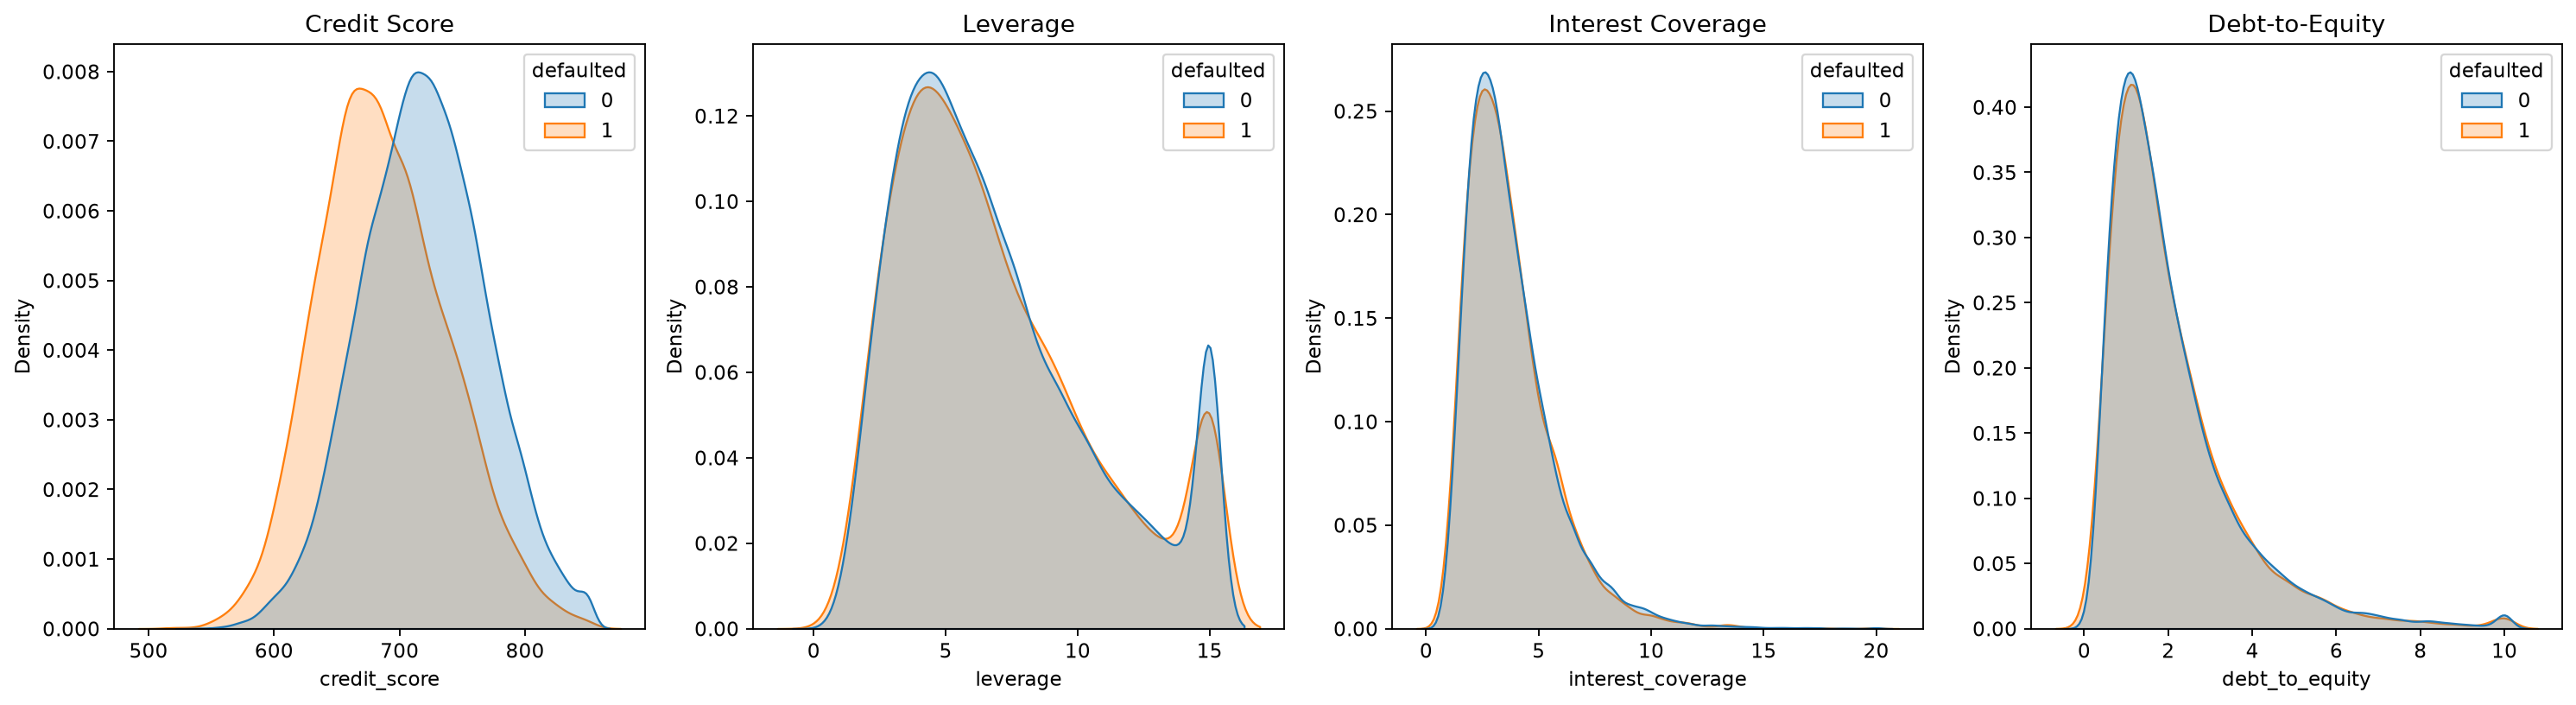

In [125]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

sns.kdeplot(data=df, x='credit_score', hue='defaulted', fill=True, common_norm=False, ax=axes[0])
axes[0].set_title('Credit Score')

sns.kdeplot(data=df, x='leverage',hue='defaulted', fill=True, common_norm=False, ax=axes[1])
axes[1].set_title('Leverage')

sns.kdeplot(data=df, x='interest_coverage', hue='defaulted', fill=True, common_norm=False, ax=axes[2])
axes[2].set_title('Interest Coverage')

sns.kdeplot(data=df, x='debt_to_equity', hue='defaulted', fill=True, common_norm=False, ax=axes[3])
axes[3].set_title('Debt-to-Equity')

plt.tight_layout()
plt.show()

Distributions of these variables across defaulted and not defaulted loans does not differ significantly except credit_score.

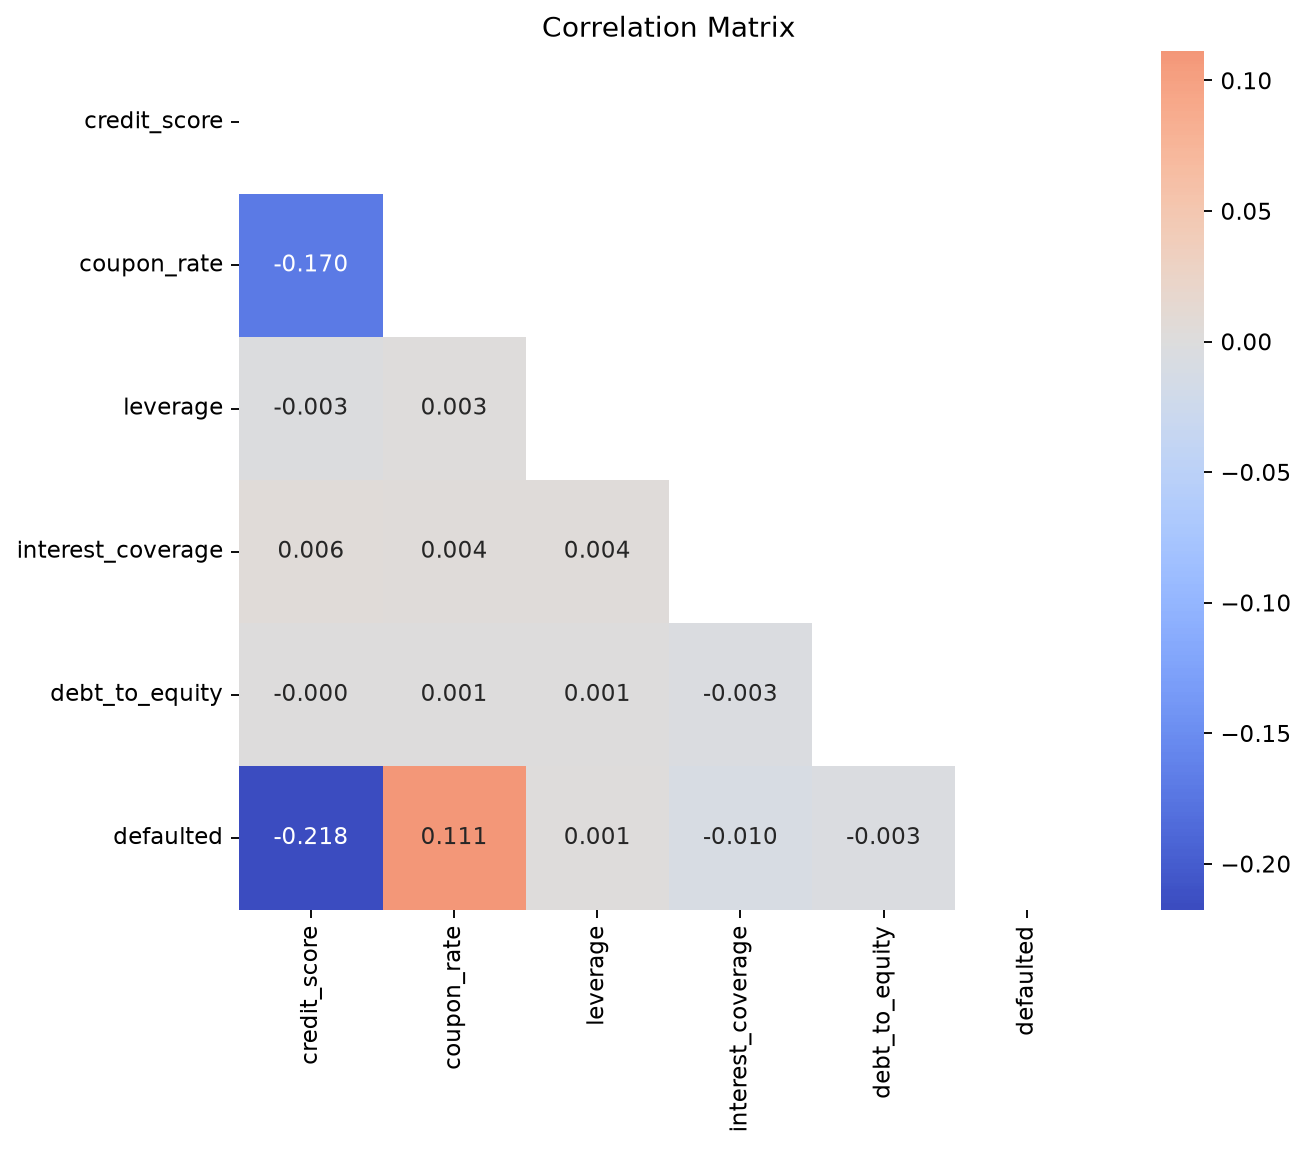

In [58]:
corr = df.select(num).corr()
plt.figure(figsize=(9, 7))

sns.heatmap(
    corr,
    annot=True,
    fmt='.3f',
    cmap='coolwarm',
    center=0,
    square=True,
    xticklabels=num, 
    yticklabels=num,
    mask=np.triu(np.ones_like(corr, dtype=bool))
)

plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

# Preprocessing and utils functions

In [ ]:
y = df['defaulted']
df = df.drop('defaulted')


X_train, X_test, y_train, y_test = train_test_split(df, y, test_size=0.2, random_state=123)

In [12]:
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

shape: (2, 2)
┌───────────┬────────────┐
│ defaulted ┆ proportion │
│ ---       ┆ ---        │
│ i64       ┆ f64        │
╞═══════════╪════════════╡
│ 0         ┆ 0.86       │
│ 1         ┆ 0.14       │
└───────────┴────────────┘
shape: (2, 2)
┌───────────┬────────────┐
│ defaulted ┆ proportion │
│ ---       ┆ ---        │
│ i64       ┆ f64        │
╞═══════════╪════════════╡
│ 0         ┆ 0.865      │
│ 1         ┆ 0.135      │
└───────────┴────────────┘


In [15]:
class FeaturesTransform(BaseEstimator):
    def __init__(self):
        pass
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        df = X.clone()

        df = df.with_columns(year=pl.col("origination_date").str.slice(0, 4)).with_columns(month=pl.col("origination_date").str.slice(5, 2))
        df = df.with_columns(pl.when(pl.col("leverage") >= 15).then(1).otherwise(0).alias("leverage_tail"))

        df = df.with_columns(leverage = pl.col('leverage').log())
        df = df.with_columns(interest_coverage = pl.col('interest_coverage').log())
        df = df.with_columns(debt_to_equity = pl.col('debt_to_equity').log())
        df = df.with_columns(loan_type_full = pl.concat_str('loan_type', 'collateral', separator='_'))

        df = df.drop('loan_type', 'collateral', 'origination_date')

        return df

In [18]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cats', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cats)
    ],
    remainder='passthrough'
)

In [ ]:
from sklearn.metrics import (accuracy_score, f1_score, log_loss, precision_score, recall_score, roc_auc_score,)


def calculate_metrics(y_test, y_pred, y_pred_proba, y_train, y_pred_train, y_pred_train_proba):

    metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC', 'LogLoss']

    test_metrics = [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_pred_proba),
        log_loss(y_test, y_pred_proba),
    ]

    train_metrics = [
        accuracy_score(y_train, y_pred_train),
        precision_score(y_train, y_pred_train),
        recall_score(y_train, y_pred_train),
        f1_score(y_train, y_pred_train),
        roc_auc_score(y_train, y_pred_train_proba),
        log_loss(y_train, y_pred_train_proba),
    ]

    return pl.DataFrame(
        {"Metrics": metrics, "Train": train_metrics, "Test": test_metrics}
    ).with_columns(
        pl.col("Train").round(3), pl.col("Test").round(3)
    )


def get_predictions(model, X_train, X_test):
   
    y_pred_train = model.predict(X_train)
    y_pred_train_proba = model.predict_proba(X_train)[:, 1]

    y_pred_test = model.predict(X_test)
    y_pred_test_proba = model.predict_proba(X_test)[:, 1]

    return (
        y_pred_train,
        y_pred_train_proba,
        y_pred_test,
        y_pred_test_proba,
    )


def plot_precision_recall_curve(y_test, y_test_pred_proba, model_name):
    precision, recall, thresholds = precision_recall_curve(y_test, y_test_pred_proba)
    plt.plot(recall, precision, marker='.', label=f"{model_name}")

    plt.xlabel('Recall')
    plt.ylabel('precision')
    plt.legend()
    plt.show()

    fscore = (2 * precision * recall) / (precision + recall)
    ix = np.argmax(fscore)
    print(f"Best treshold {thresholds[ix].round(3)}, best F1 score {fscore[ix].round(3)}")

# Estimation

## Logistic Regression

### Tuning

In [88]:
pipe_lr = Pipeline(
    steps=[
        ('features', FeaturesTransform()),
        ('ohe', preprocessor),
        ('scaler', StandardScaler()),
        ('lr', LogisticRegression(max_iter=100))
    ]
)

param_grid = {
    'lr__penalty': ['l1', 'l2'],
    'lr__C': np.logspace(-4, 4, 20),
    'lr__solver': ['liblinear']
}

lr_grid_search = GridSearchCV(pipe_lr, param_grid=param_grid, cv=5, return_train_score=True, scoring='roc_auc')
tuned_lr = TunedThresholdClassifierCV(estimator=lr_grid_search, scoring='f1', cv=5, thresholds=100)
tuned_lr.fit(X_train, y_train)

,"estimator estimator: estimator instanceThe classifier, fitted or not, for which we want to optimizethe decision threshold used during `predict`.",GridSearchCV(...ing='roc_auc')
,"scoring scoring: str or callable, default=""balanced_accuracy""The objective metric to be optimized. Can be one of:- str: string associated to a scoring function for binary classification, see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.",'f1'
,"cv cv: int, float, cross-validation generator, iterable or ""prefit"", default=NoneDetermines the cross-validation splitting strategy to train classifier.Possible inputs for cv are:* `None`, to use the default 5-fold stratified K-fold cross validation;* An integer number, to specify the number of folds in a stratified k-fold;* A float number, to specify a single shuffle split. The floating number should be in (0, 1) and represent the size of the validation set;* An object to be used as a cross-validation generator;* An iterable yielding train, test splits;* `""prefit""`, to bypass the cross-validation.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... warning:: Using `cv=""prefit""` and passing the same dataset for fitting `estimator` and tuning the cut-off point is subject to undesired overfitting. You can refer to :ref:`TunedThresholdClassifierCV_no_cv` for an example. This option should only be used when the set used to fit `estimator` is different from the one used to tune the cut-off point (by calling :meth:`TunedThresholdClassifierCV.fit`).",5
,"response_method response_method: {""auto"", ""decision_function"", ""predict_proba""}, default=""auto""Methods by the classifier `estimator` corresponding to thedecision function for which we want to find a threshold. It can be:* if `""auto""`, it will try to invoke, for each classifier, `""predict_proba""` or `""decision_function""` in that order.* otherwise, one of `""predict_proba""` or `""decision_function""`. If the method is not implemented by the classifier, it will raise an error.",'auto'
,"thresholds thresholds: int or array-like, default=100The number of decision threshold to use when discretizing the output of theclassifier `method`. Pass an array-like to manually specify the thresholdsto use.",100
,"refit refit: bool, default=TrueWhether or not to refit the classifier on the entire training set oncethe decision threshold has been found.Note that forcing `refit=False` on cross-validation having morethan a single split will raise an error. Similarly, `refit=True` inconjunction with `cv=""prefit""` will raise an error.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. When `cv` represents across-validation strategy, the fitting and scoring on each data splitis done in parallel. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of cross-validation when `cv` is a float.See :term:`Glossary <random_state>`.",None
,"store_cv_results store_cv_results: bool, default=FalseWhether to store all scores and thresholds computed during the cross-validationprocess.",False
Name,Type,Value
"best_score_ best_score_: float or NoneThe optimal score of the objective metric, evaluated at `best_threshold_`.",float64,0.4475


In [16]:
tuned_lr.estimator_

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'lr__C': array([1.0000...00000000e+04]), 'lr__penalty': ['l1', 'l2'], 'lr__solver': ['liblinear']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of the

In [18]:
cv_mean_scores = []
cv_std = []
for splits in range(2, 11):
    cv = StratifiedKFold(n_splits=splits, random_state=2026, shuffle=True)
    cv_score = cross_validate(tuned_lr.estimator_.best_estimator_, X_test, y_test, cv=cv, scoring='roc_auc')
    cv_mean_scores.append(cv_score['test_score'].mean())
    cv_std.append(cv_score['test_score'].std())

cv_mean_scores = np.array(cv_mean_scores)
cv_std = np.array(cv_std)

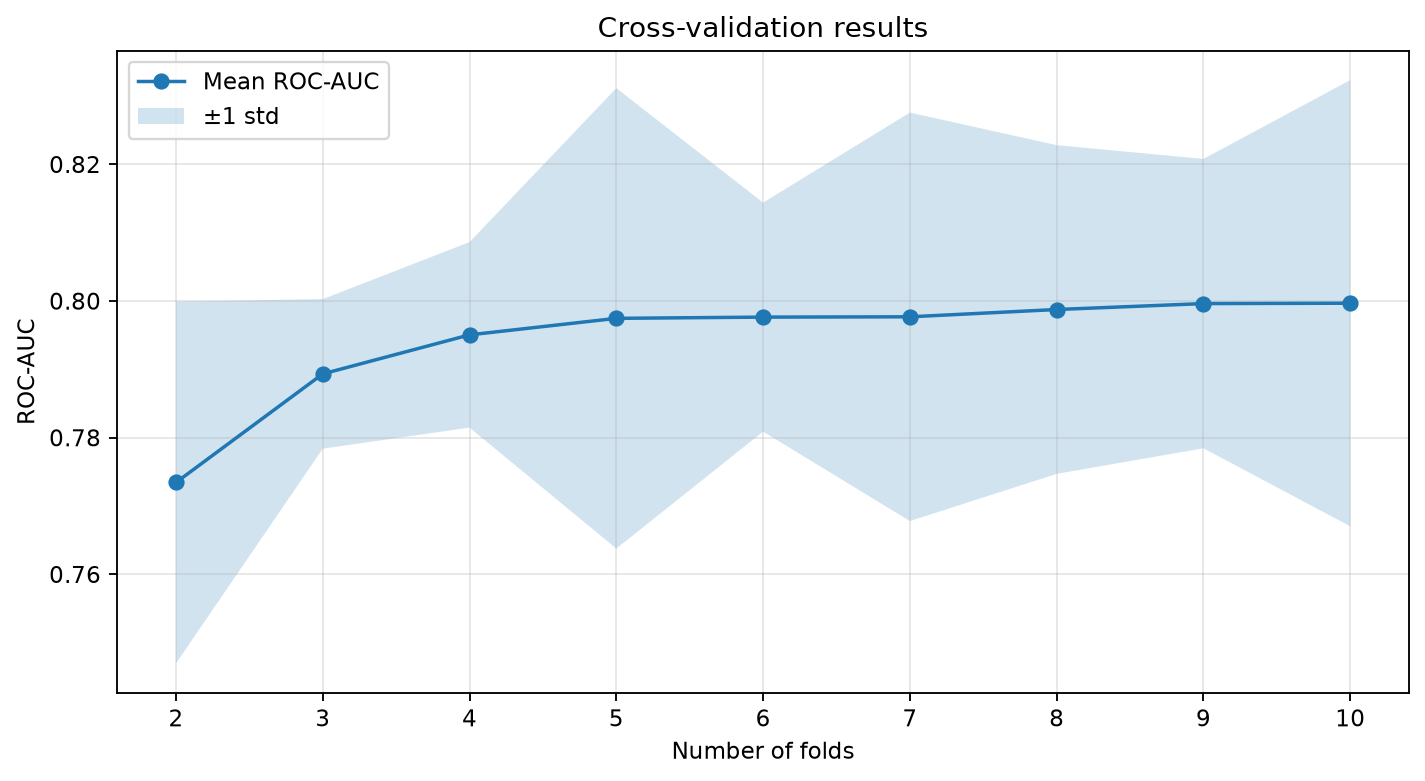

In [19]:
plt.figure(figsize=(10, 5))
plt.plot(
    range(2, 11),
    cv_mean_scores,
    marker='o',
    label='Mean ROC-AUC'
)
plt.fill_between(
    range(2, 11),
    cv_mean_scores - 1.96 * cv_std,
    cv_mean_scores + 1.96 * cv_std,
    alpha=0.2,
    label='±1 std'
)
plt.xlabel('Number of folds')
plt.ylabel('ROC-AUC')
plt.title('Cross-validation results')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Metrics

In [283]:
print(tuned_lr.best_score_)

0.44749888467181825


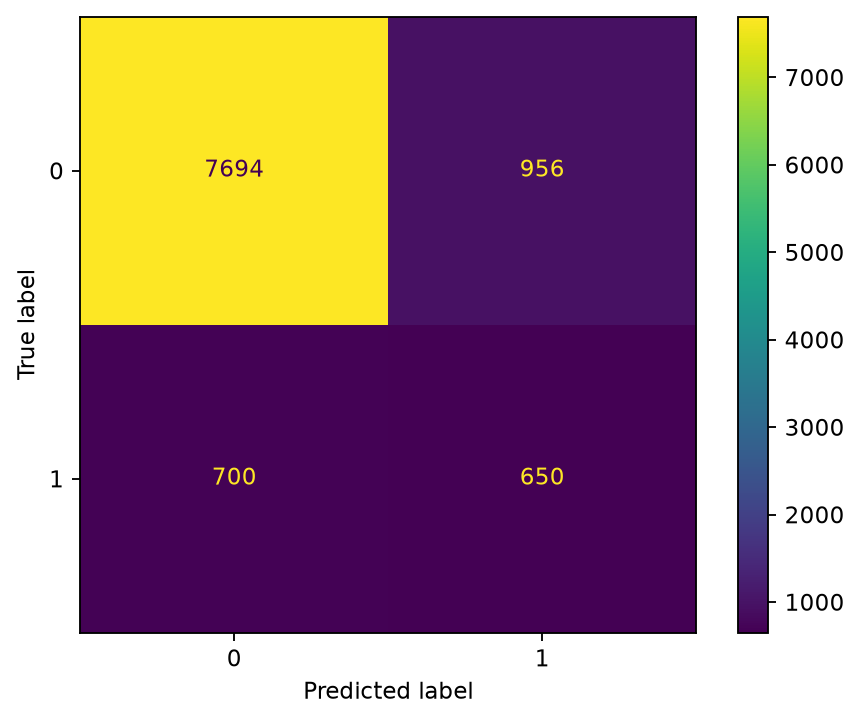

In [285]:
ConfusionMatrixDisplay.from_estimator(tuned_lr, X_test, y_test)

In [286]:
y_pred_train, y_pred_train_proba, y_test_pred, y_test_pred_proba = get_predictions(tuned_lr, X_train, X_test)
print(calculate_metrics(y_test, y_test_pred, y_test_pred_proba, y_train, y_pred_train, y_pred_train_proba))

shape: (6, 3)
┌───────────┬───────┬───────┐
│ Metrics   ┆ Train ┆ Test  │
│ ---       ┆ ---   ┆ ---   │
│ str       ┆ f64   ┆ f64   │
╞═══════════╪═══════╪═══════╡
│ Accuracy  ┆ 0.833 ┆ 0.834 │
│ Precision ┆ 0.417 ┆ 0.405 │
│ Recall    ┆ 0.485 ┆ 0.481 │
│ F1-score  ┆ 0.449 ┆ 0.44  │
│ ROC-AUC   ┆ 0.807 ┆ 0.807 │
│ LogLoss   ┆ 0.326 ┆ 0.321 │
└───────────┴───────┴───────┘


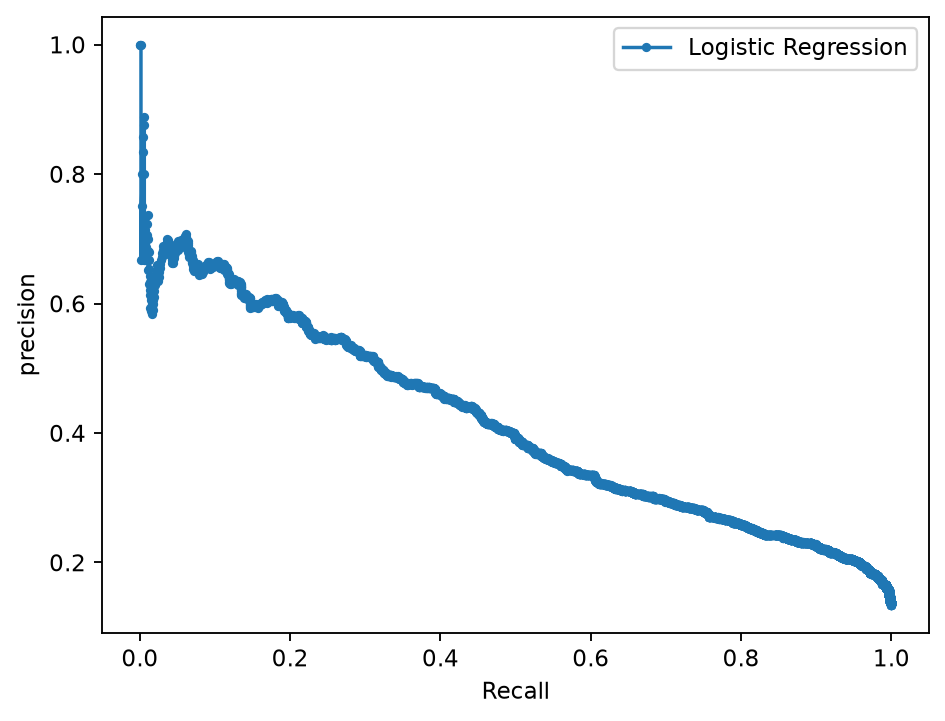

Best treshold 0.216, best F1 score 0.444


In [ ]:
plot_precision_recall_curve(y_test, y_test_pred_proba, 'Logistic Regression')

## Decision Tree

### Tuning

In [90]:
pipe_dtc = Pipeline(
    steps=[
        ('features', FeaturesTransform()),
        ('ohe', preprocessor),
        ('dt', DecisionTreeClassifier())
    ]
)

param_grid_dt = {
    'dt__criterion': ['gini', 'entropy'],
    'dt__max_depth': np.arange(1, 21, 1),
    'dt__min_samples_split': [3,4,5,6,7,8,9,10],
    'dt__min_samples_leaf': [1, 2, 3],
    'dt__max_features': ['sqrt', 'log2']
}

dt_grid_search = GridSearchCV(estimator=pipe_dtc, param_grid=param_grid_dt, cv=5, scoring='roc_auc', n_jobs=-1, return_train_score=True)
tuned_dt = TunedThresholdClassifierCV(estimator=dt_grid_search, scoring='f1', cv=5, thresholds=100)
tuned_dt.fit(X_train, y_train)

,"estimator estimator: estimator instanceThe classifier, fitted or not, for which we want to optimizethe decision threshold used during `predict`.",GridSearchCV(...ing='roc_auc')
,"scoring scoring: str or callable, default=""balanced_accuracy""The objective metric to be optimized. Can be one of:- str: string associated to a scoring function for binary classification, see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.",'f1'
,"cv cv: int, float, cross-validation generator, iterable or ""prefit"", default=NoneDetermines the cross-validation splitting strategy to train classifier.Possible inputs for cv are:* `None`, to use the default 5-fold stratified K-fold cross validation;* An integer number, to specify the number of folds in a stratified k-fold;* A float number, to specify a single shuffle split. The floating number should be in (0, 1) and represent the size of the validation set;* An object to be used as a cross-validation generator;* An iterable yielding train, test splits;* `""prefit""`, to bypass the cross-validation.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... warning:: Using `cv=""prefit""` and passing the same dataset for fitting `estimator` and tuning the cut-off point is subject to undesired overfitting. You can refer to :ref:`TunedThresholdClassifierCV_no_cv` for an example. This option should only be used when the set used to fit `estimator` is different from the one used to tune the cut-off point (by calling :meth:`TunedThresholdClassifierCV.fit`).",5
,"response_method response_method: {""auto"", ""decision_function"", ""predict_proba""}, default=""auto""Methods by the classifier `estimator` corresponding to thedecision function for which we want to find a threshold. It can be:* if `""auto""`, it will try to invoke, for each classifier, `""predict_proba""` or `""decision_function""` in that order.* otherwise, one of `""predict_proba""` or `""decision_function""`. If the method is not implemented by the classifier, it will raise an error.",'auto'
,"thresholds thresholds: int or array-like, default=100The number of decision threshold to use when discretizing the output of theclassifier `method`. Pass an array-like to manually specify the thresholdsto use.",100
,"refit refit: bool, default=TrueWhether or not to refit the classifier on the entire training set oncethe decision threshold has been found.Note that forcing `refit=False` on cross-validation having morethan a single split will raise an error. Similarly, `refit=True` inconjunction with `cv=""prefit""` will raise an error.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. When `cv` represents across-validation strategy, the fitting and scoring on each data splitis done in parallel. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of cross-validation when `cv` is a float.See :term:`Glossary <random_state>`.",None
,"store_cv_results store_cv_results: bool, default=FalseWhether to store all scores and thresholds computed during the cross-validationprocess.",False
Name,Type,Value
"best_score_ best_score_: float or NoneThe optimal score of the objective metric, evaluated at `best_threshold_`.",float64,0.3761


In [294]:
tuned_dt.estimator_

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'dt__criterion': ['gini', 'entropy'], 'dt__max_depth': array([ 1, 2... 18, 19, 20]), 'dt__max_features': ['sqrt', 'log2'], 'dt__min_samples_leaf': [1, 2, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_pa

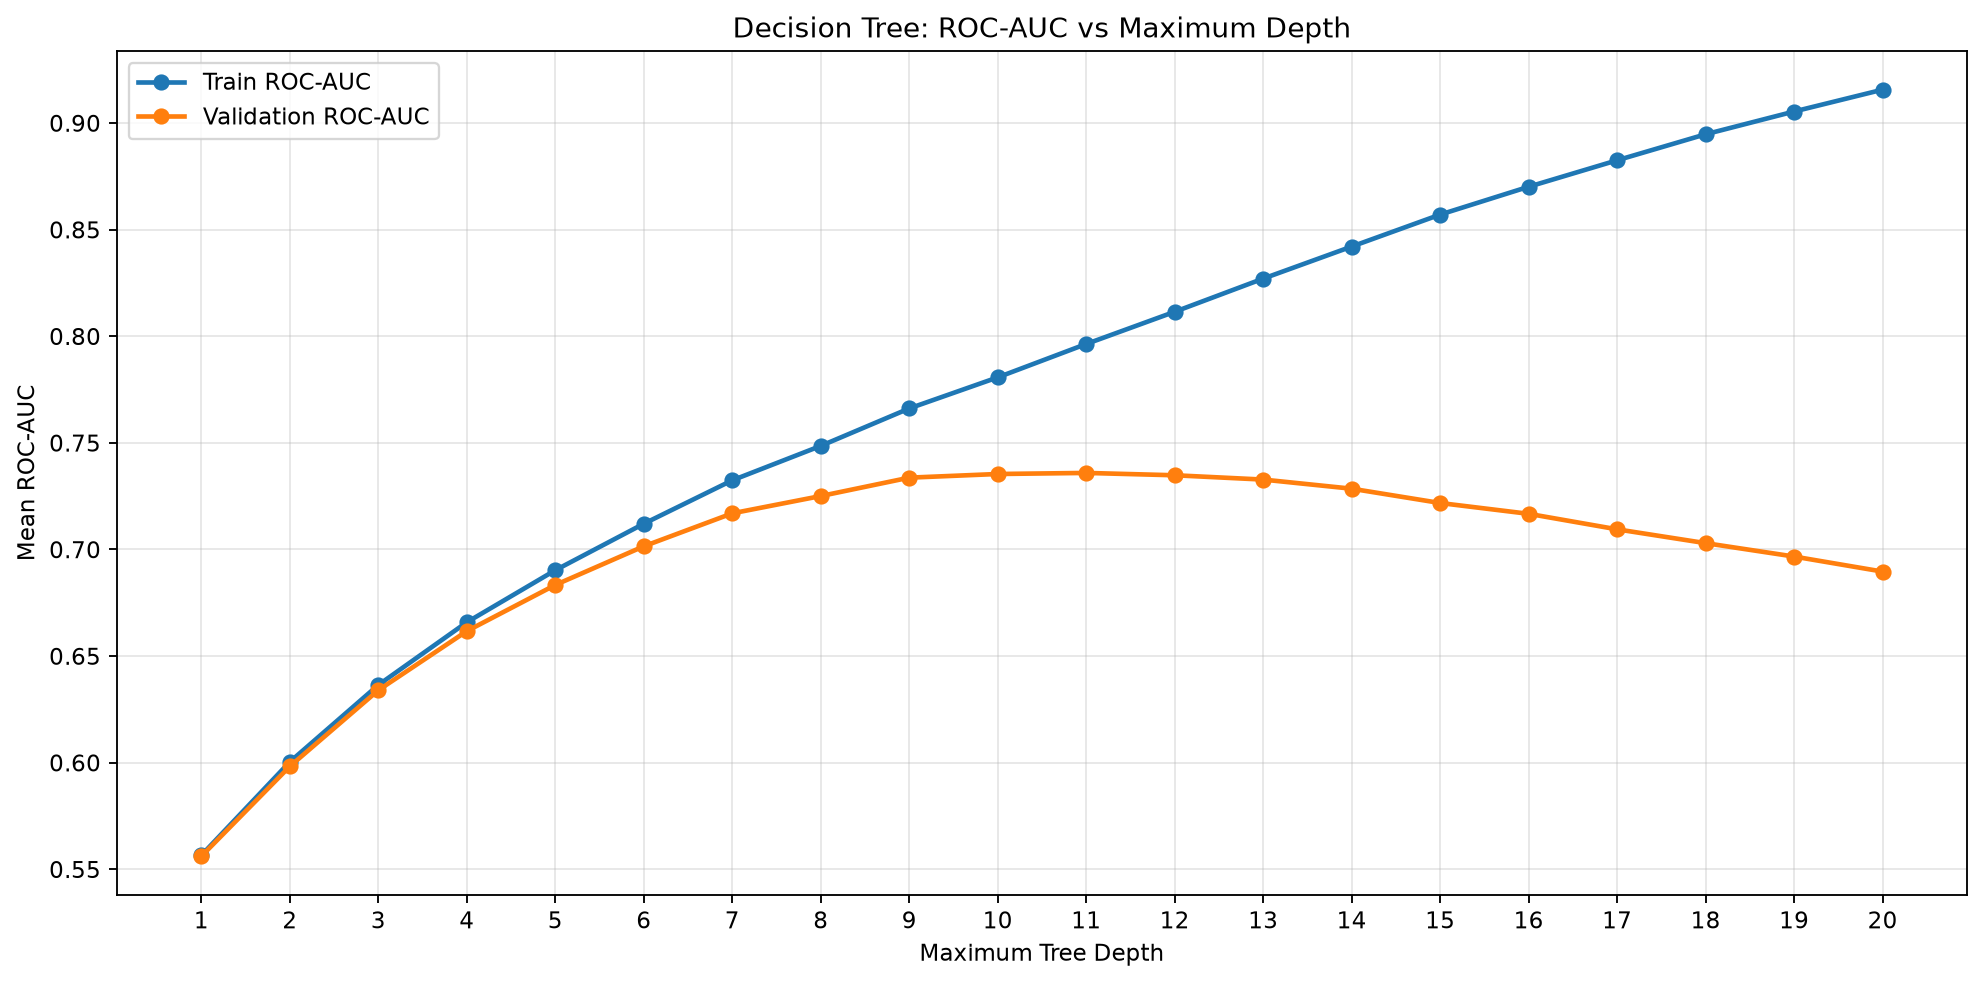

In [299]:
cv_results = pl.DataFrame(tuned_dt.estimator_.cv_results_)


depth_scores = (
    cv_results
    .group_by('param_dt__max_depth')
    .agg(
        pl.col('mean_train_score').mean().alias('train_auc'),
        pl.col('mean_test_score').mean().alias('val_auc')
    )
    .with_columns(
        pl.col('param_dt__max_depth')
        .cast(pl.Int64, strict=False)
        .alias('depth')
    )
    .sort('depth', nulls_last=True)
)


depth_labels = [
    str(depth) if depth is not None else 'None'
    for depth in depth_scores['depth'].to_list()
]

plt.figure(figsize=(12, 6))
plt.plot(depth_labels, depth_scores['train_auc'].to_numpy(), marker='o', linewidth=2, label='Train ROC-AUC')
plt.plot(depth_labels, depth_scores['val_auc'].to_numpy(), marker='o', linewidth=2, label='Validation ROC-AUC')
plt.xlabel('Maximum Tree Depth')
plt.ylabel('Mean ROC-AUC')
plt.title('Decision Tree: ROC-AUC vs Maximum Depth')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Metrics

In [300]:
print(tuned_dt.best_score_)

0.39668152769395065


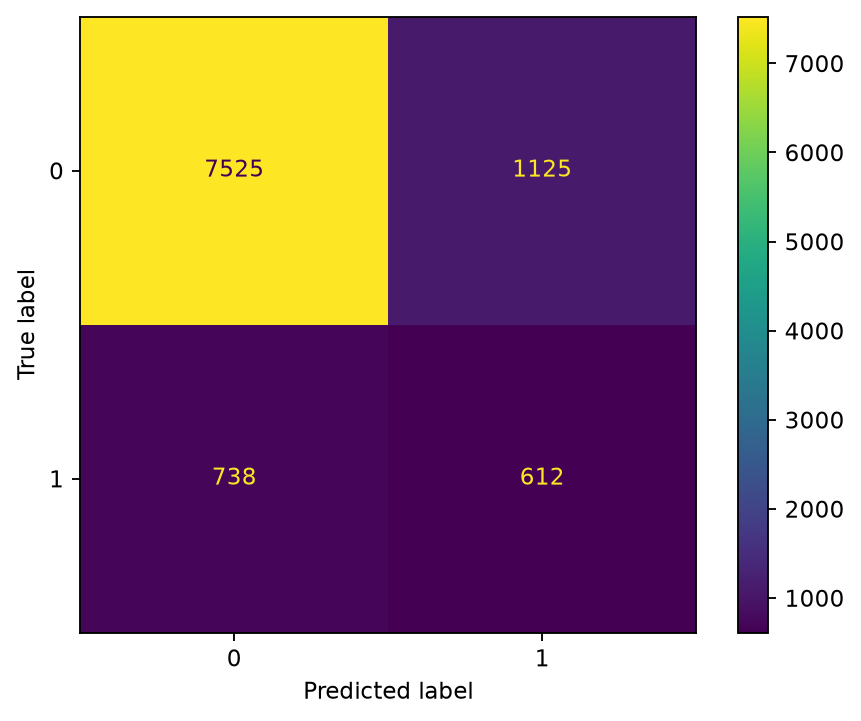

In [301]:
ConfusionMatrixDisplay.from_estimator(tuned_dt, X_test, y_test)

In [302]:
y_pred_train, y_pred_train_proba, y_test_pred, y_test_pred_proba = get_predictions(tuned_dt, X_train, X_test)
print(calculate_metrics(y_test, y_test_pred, y_test_pred_proba, y_train, y_pred_train, y_pred_train_proba))

shape: (6, 3)
┌───────────┬───────┬───────┐
│ Metrics   ┆ Train ┆ Test  │
│ ---       ┆ ---   ┆ ---   │
│ str       ┆ f64   ┆ f64   │
╞═══════════╪═══════╪═══════╡
│ Accuracy  ┆ 0.819 ┆ 0.814 │
│ Precision ┆ 0.384 ┆ 0.352 │
│ Recall    ┆ 0.478 ┆ 0.453 │
│ F1-score  ┆ 0.425 ┆ 0.397 │
│ ROC-AUC   ┆ 0.779 ┆ 0.75  │
│ LogLoss   ┆ 0.332 ┆ 0.421 │
└───────────┴───────┴───────┘


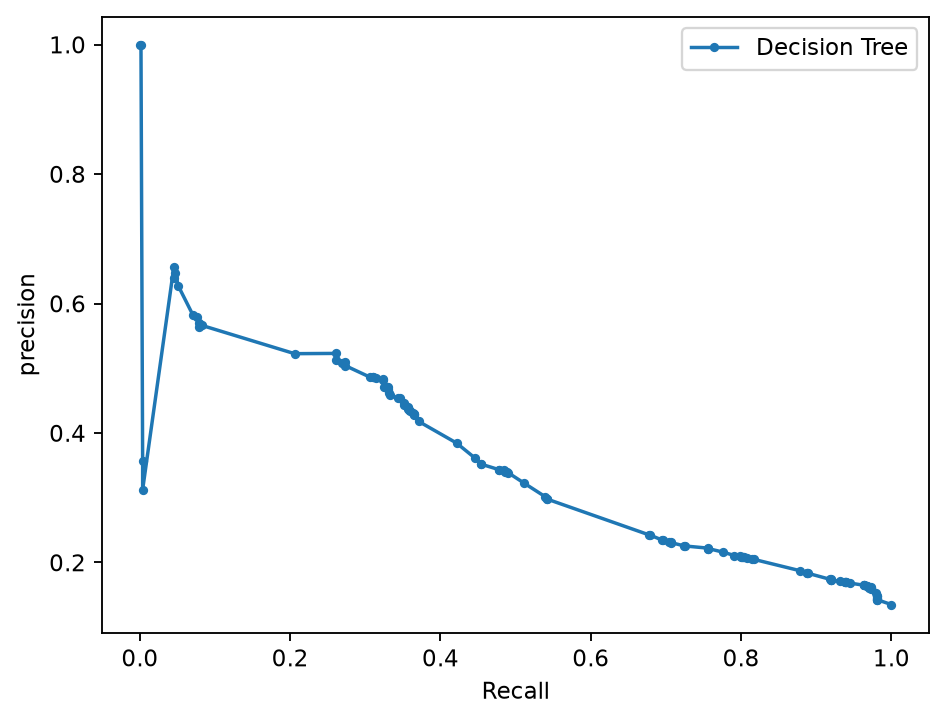

Best treshold 0.212, best F1 score 0.402


In [ ]:
plot_precision_recall_curve(y_test, y_test_pred_proba, 'Decision Tree')

### Interpretation

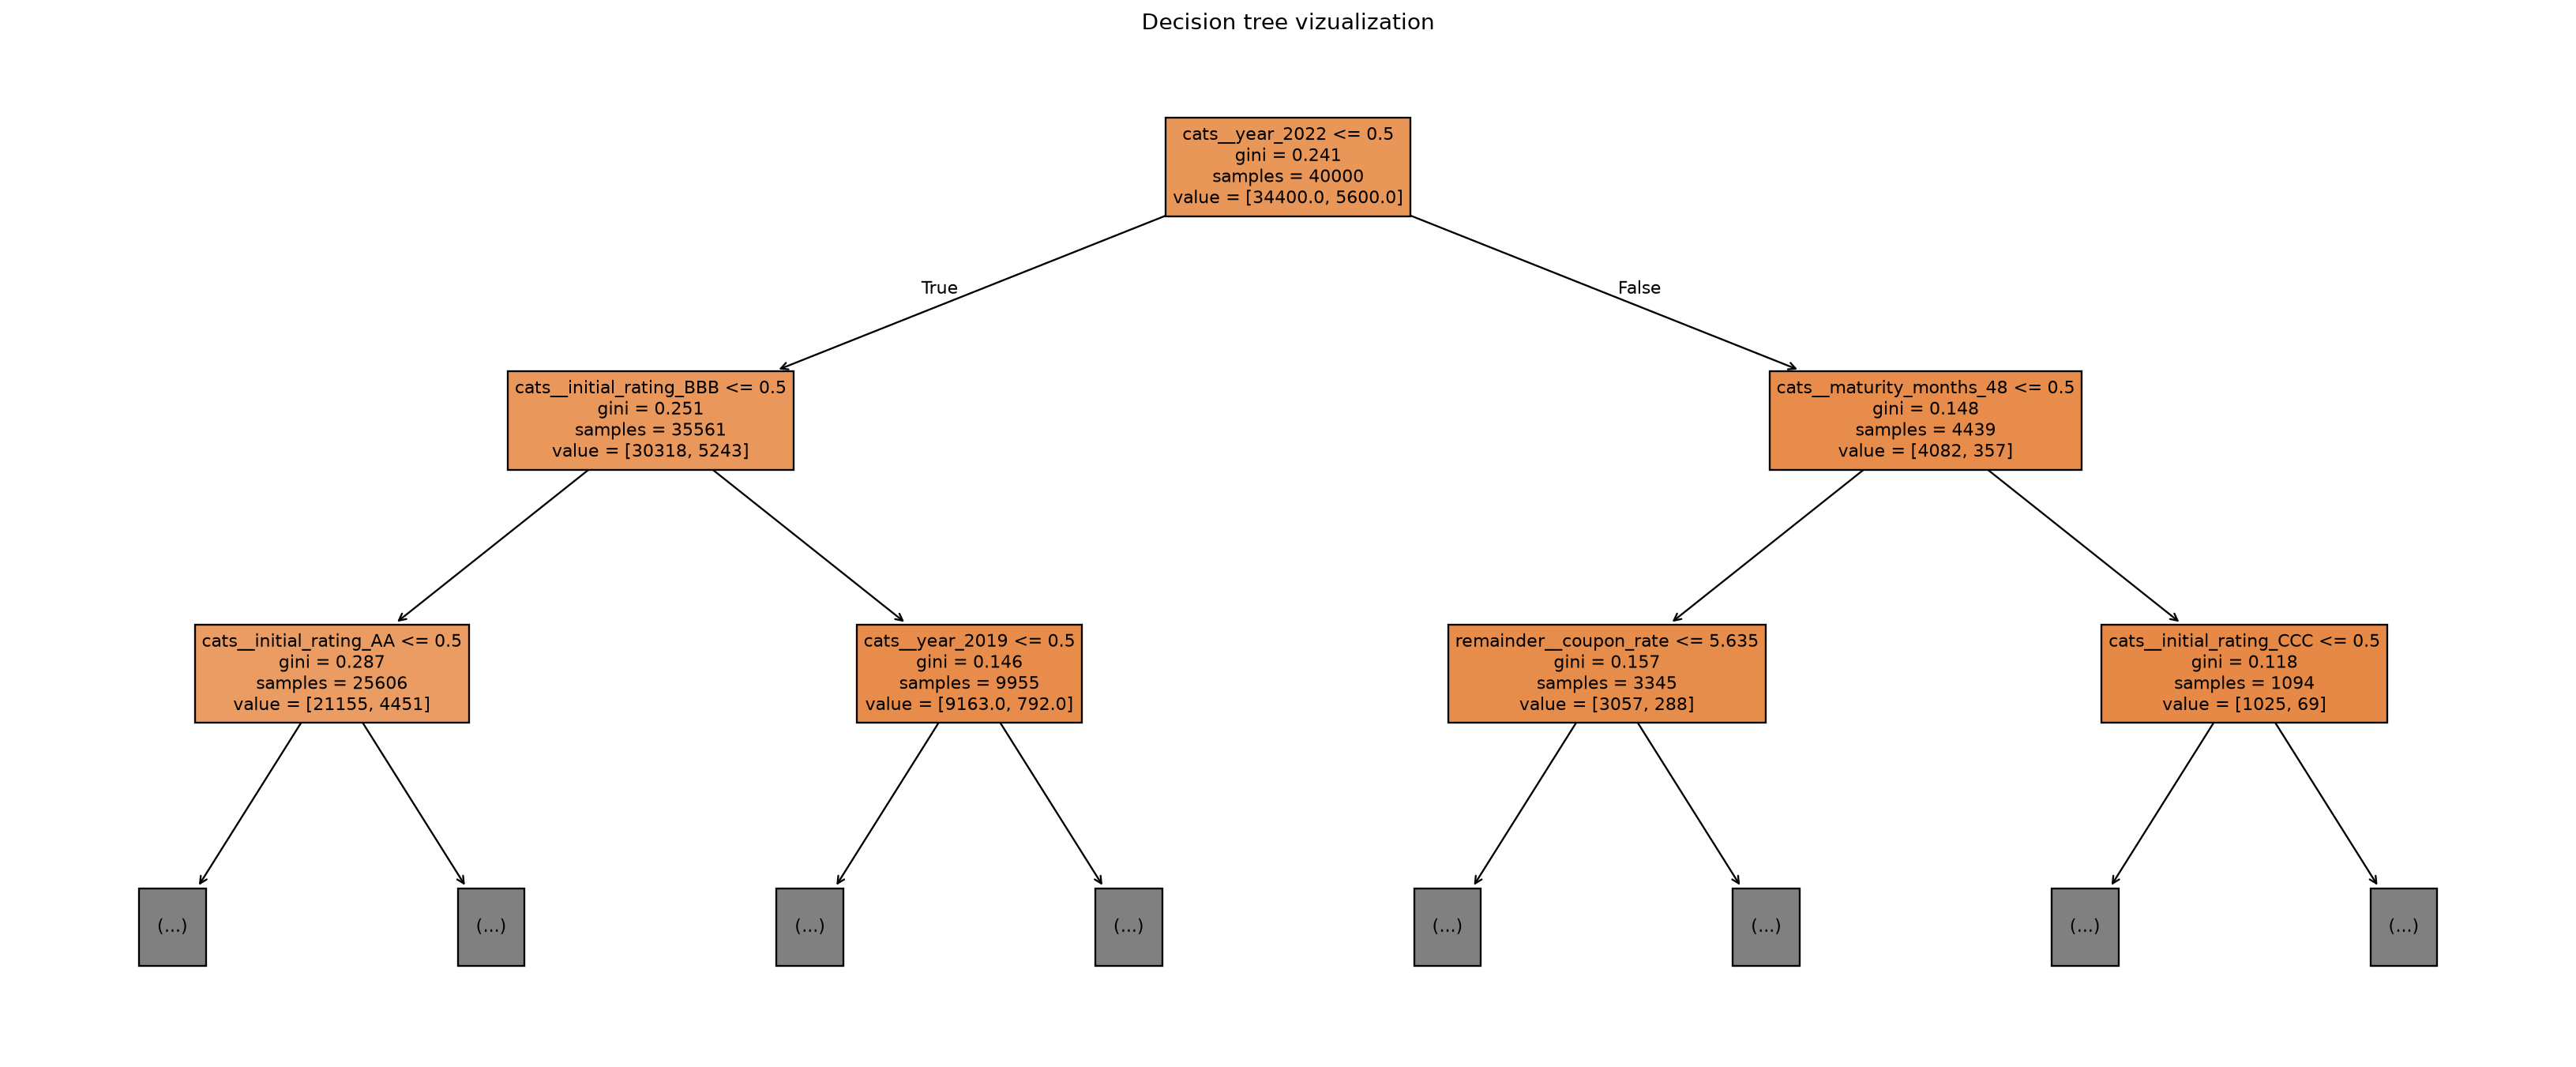

In [306]:
X_transformed = tuned_dt.estimator_.best_estimator_.named_steps['features'].transform(X_train)
feature_names = tuned_dt.estimator_.best_estimator_.named_steps['ohe'].get_feature_names_out(X_transformed.columns)

plt.figure(figsize=(25, 10))
plot_tree(tuned_dt.estimator_.best_estimator_['dt'], filled=True, max_depth=2, feature_names=feature_names)
plt.title("Decision tree vizualization")
plt.show()

## kNN

### Tuning

In [87]:
pipe_knn = Pipeline(
    steps=[
        ('features', FeaturesTransform()),
        ('ohe', preprocessor),
        ('scaler', StandardScaler()),
        ('knn',  KNeighborsClassifier())
    ]
)

neighbors_max = int(X_train.shape[0]**0.5)

param_grid_knn = {
    'knn__n_neighbors': np.arange(1, neighbors_max+1, 2)
}

knn_grid_search = GridSearchCV(estimator=pipe_knn, param_grid=param_grid_knn, cv=5, scoring='roc_auc', n_jobs=-1, return_train_score=True)
tuned_knn = TunedThresholdClassifierCV(estimator=knn_grid_search, scoring='f1', cv=5, thresholds=100)
tuned_knn.fit(X_train, y_train)

,"estimator estimator: estimator instanceThe classifier, fitted or not, for which we want to optimizethe decision threshold used during `predict`.",GridSearchCV(...ing='roc_auc')
,"scoring scoring: str or callable, default=""balanced_accuracy""The objective metric to be optimized. Can be one of:- str: string associated to a scoring function for binary classification, see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.",'f1'
,"cv cv: int, float, cross-validation generator, iterable or ""prefit"", default=NoneDetermines the cross-validation splitting strategy to train classifier.Possible inputs for cv are:* `None`, to use the default 5-fold stratified K-fold cross validation;* An integer number, to specify the number of folds in a stratified k-fold;* A float number, to specify a single shuffle split. The floating number should be in (0, 1) and represent the size of the validation set;* An object to be used as a cross-validation generator;* An iterable yielding train, test splits;* `""prefit""`, to bypass the cross-validation.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... warning:: Using `cv=""prefit""` and passing the same dataset for fitting `estimator` and tuning the cut-off point is subject to undesired overfitting. You can refer to :ref:`TunedThresholdClassifierCV_no_cv` for an example. This option should only be used when the set used to fit `estimator` is different from the one used to tune the cut-off point (by calling :meth:`TunedThresholdClassifierCV.fit`).",5
,"response_method response_method: {""auto"", ""decision_function"", ""predict_proba""}, default=""auto""Methods by the classifier `estimator` corresponding to thedecision function for which we want to find a threshold. It can be:* if `""auto""`, it will try to invoke, for each classifier, `""predict_proba""` or `""decision_function""` in that order.* otherwise, one of `""predict_proba""` or `""decision_function""`. If the method is not implemented by the classifier, it will raise an error.",'auto'
,"thresholds thresholds: int or array-like, default=100The number of decision threshold to use when discretizing the output of theclassifier `method`. Pass an array-like to manually specify the thresholdsto use.",100
,"refit refit: bool, default=TrueWhether or not to refit the classifier on the entire training set oncethe decision threshold has been found.Note that forcing `refit=False` on cross-validation having morethan a single split will raise an error. Similarly, `refit=True` inconjunction with `cv=""prefit""` will raise an error.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. When `cv` represents across-validation strategy, the fitting and scoring on each data splitis done in parallel. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of cross-validation when `cv` is a float.See :term:`Glossary <random_state>`.",None
,"store_cv_results store_cv_results: bool, default=FalseWhether to store all scores and thresholds computed during the cross-validationprocess.",False
Name,Type,Value
"best_score_ best_score_: float or NoneThe optimal score of the objective metric, evaluated at `best_threshold_`.",float64,0.4319


In [308]:
tuned_knn.estimator_

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'knn__n_neighbors': array([ 1, ...95, 197, 199])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See 

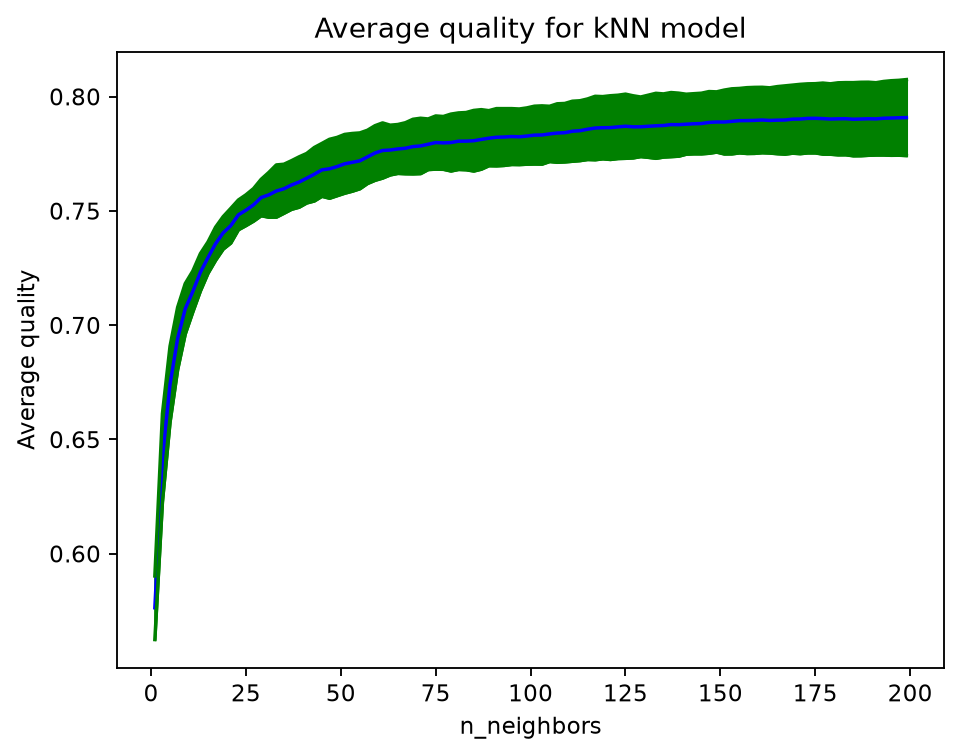

In [318]:
means = tuned_knn.estimator_.cv_results_['mean_test_score']
stds = tuned_knn.estimator_.cv_results_['std_test_score']
error = 1.95 * stds
n_neighbors = tuned_knn.estimator_.cv_results_['param_knn__n_neighbors'].astype(int)
plt.plot(n_neighbors, means, color = 'blue')
plt.plot(n_neighbors, means - error, color = 'green')
plt.plot(n_neighbors, means + error, color = 'green')
plt.fill_between(n_neighbors, means - error, means + error, color = 'green')
plt.xlabel('n_neighbors')
plt.ylabel('Average quality')
plt.title('Average quality for kNN model') 
plt.show()

### Metrics

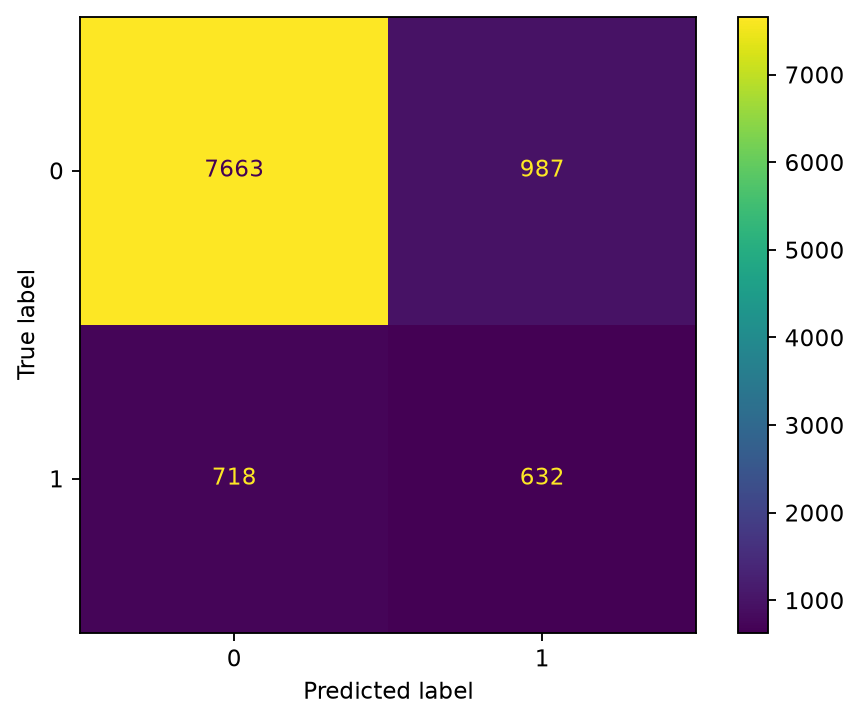

In [319]:
ConfusionMatrixDisplay.from_estimator(tuned_knn, X_test, y_test)

In [320]:
y_pred_train, y_pred_train_proba, y_test_pred, y_test_pred_proba = get_predictions(tuned_knn, X_train, X_test)
print(calculate_metrics(y_test, y_test_pred, y_test_pred_proba, y_train, y_pred_train, y_pred_train_proba))

shape: (6, 3)
┌───────────┬───────┬───────┐
│ Metrics   ┆ Train ┆ Test  │
│ ---       ┆ ---   ┆ ---   │
│ str       ┆ f64   ┆ f64   │
╞═══════════╪═══════╪═══════╡
│ Accuracy  ┆ 0.833 ┆ 0.83  │
│ Precision ┆ 0.416 ┆ 0.39  │
│ Recall    ┆ 0.479 ┆ 0.468 │
│ F1-score  ┆ 0.445 ┆ 0.426 │
│ ROC-AUC   ┆ 0.809 ┆ 0.797 │
│ LogLoss   ┆ 0.344 ┆ 0.34  │
└───────────┴───────┴───────┘


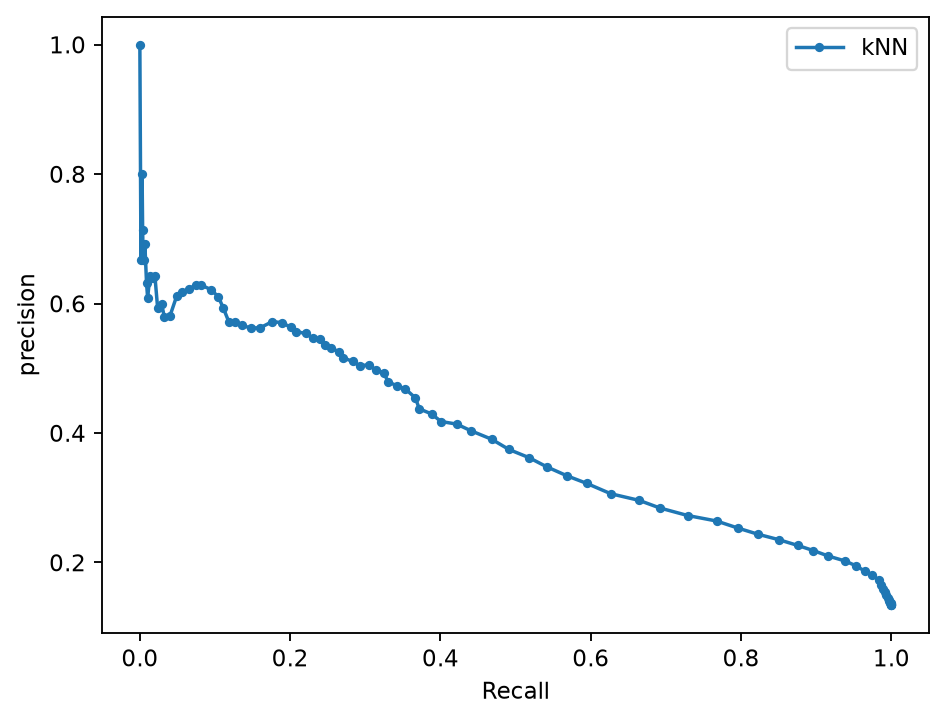

Best treshold 0.176, best F1 score 0.426


In [ ]:
plot_precision_recall_curve(y_test, y_test_pred_proba, 'kNN')

### Interpretation

Text(0.5, 1.0, 'Two classes on PCA: y_test')

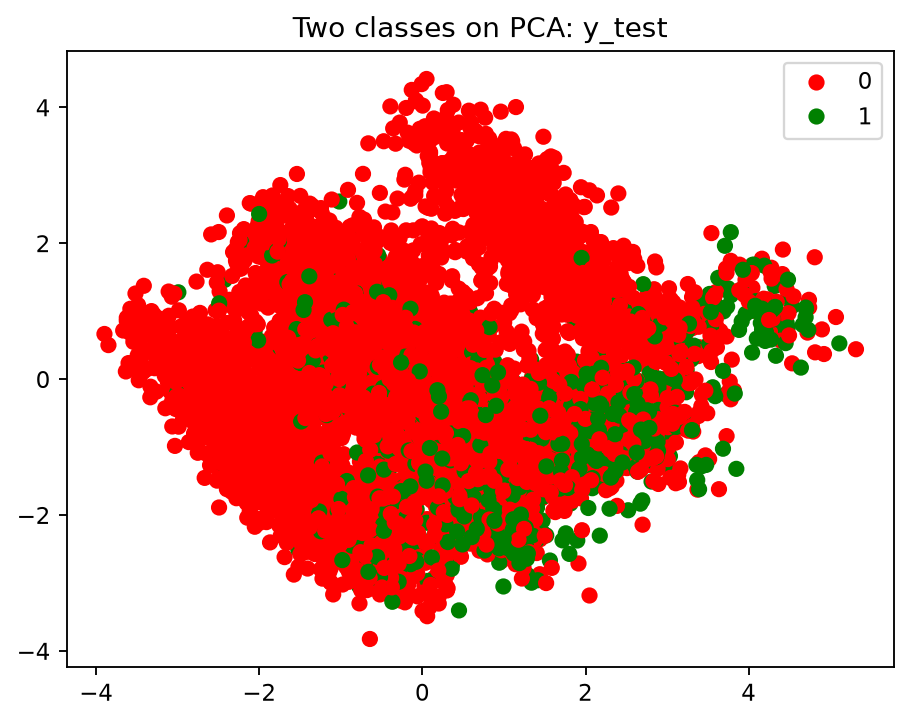

In [325]:
pca = make_pipeline(
    tuned_knn.estimator_.best_estimator_['features'],
    tuned_knn.estimator_.best_estimator_['ohe'],
    tuned_knn.estimator_.best_estimator_['scaler'],
    PCA(n_components=2, random_state=2026)
)

X_embedded = pca.fit_transform(X_test)
colors = ListedColormap(['r', 'g'])
scatter = plt.scatter(X_embedded[:, 0], X_embedded[:, 1], c=y_test, cmap=colors)
plt.legend(*scatter.legend_elements())
plt.title('Two classes on PCA: y_test')

The picture above demonstrates the projection of the observation points onto the subspace spanned by the first two main components. The points are coloured according to their labels. As we can see, the subspaces of defaulted and non-defaulted borrowers are not quite separable, but some borrowers clearly form clusters, therefore prediction based on the nearest neighbours may be logical. However, the model's metrics decline on the validation set pointing out overfitting.

## ROC-AUC Curve for LR, DT and kNN

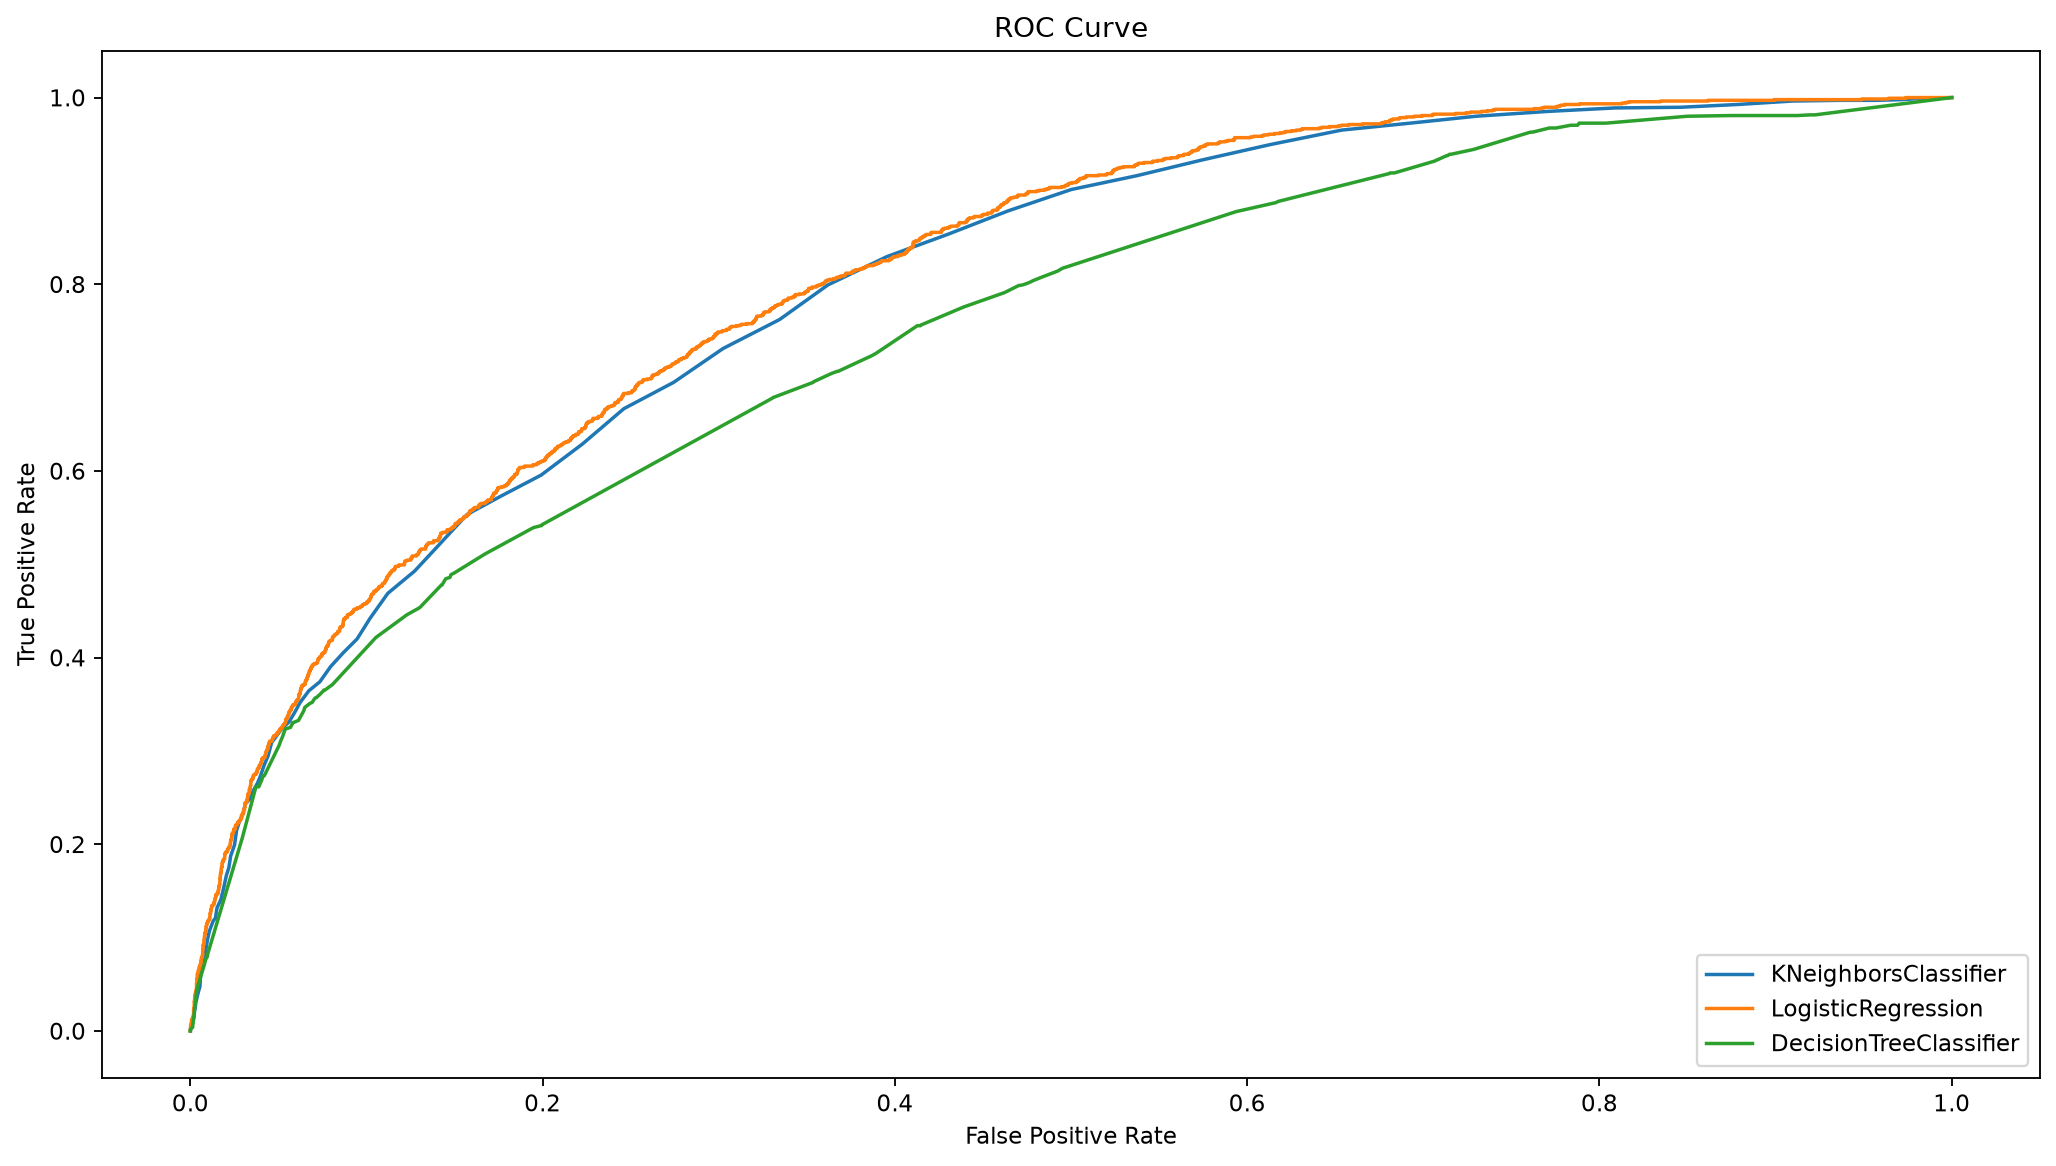

In [ ]:
from sklearn. metrics import roc_curve


kNN_model = tuned_knn.estimator_.best_estimator_ 
LR_model = tuned_lr.estimator_.best_estimator_ 
DT_model = tuned_dt.estimator_.best_estimator_ 


fig = plt.figure(figsize=(15,8))
ax = fig.add_subplot(1,1,1)
ax.set_xlim([-0.05,1.05])
ax.set_ylim([-0.05,1.05])
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve')
for model in [kNN_model, LR_model, DT_model]:
    scores = model.predict_proba(X_test)[:, 1]
    tpr, fpr, _ = roc_curve(y_test, scores)
    ax.plot(tpr, fpr, label=model[-1].__class__.__name__)
ax.legend(loc='lower right')
plt.show()

# Ansembling

## Voting

### Tuning

In [89]:
pipe_vc = VotingClassifier(
    estimators=[
        ('LR', pipe_lr),
        ('kNN', pipe_knn)
    ], 
    voting='soft'
)

param_grid_vc = {
    # Convex linear combinations
    'weights': [[i, 1-i] for i in np.arange(0, 1.1, 0.1)]
}

vc_grid_search = GridSearchCV(estimator=pipe_vc, param_grid=param_grid_vc, cv=5, scoring='roc_auc', n_jobs=-1, return_train_score=True)
tuned_vc = TunedThresholdClassifierCV(estimator=vc_grid_search, scoring='f1', cv=5, thresholds=100)
tuned_vc.fit(X_train, y_train)

,"estimator estimator: estimator instanceThe classifier, fitted or not, for which we want to optimizethe decision threshold used during `predict`.",GridSearchCV(...ing='roc_auc')
,"scoring scoring: str or callable, default=""balanced_accuracy""The objective metric to be optimized. Can be one of:- str: string associated to a scoring function for binary classification, see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.",'f1'
,"cv cv: int, float, cross-validation generator, iterable or ""prefit"", default=NoneDetermines the cross-validation splitting strategy to train classifier.Possible inputs for cv are:* `None`, to use the default 5-fold stratified K-fold cross validation;* An integer number, to specify the number of folds in a stratified k-fold;* A float number, to specify a single shuffle split. The floating number should be in (0, 1) and represent the size of the validation set;* An object to be used as a cross-validation generator;* An iterable yielding train, test splits;* `""prefit""`, to bypass the cross-validation.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... warning:: Using `cv=""prefit""` and passing the same dataset for fitting `estimator` and tuning the cut-off point is subject to undesired overfitting. You can refer to :ref:`TunedThresholdClassifierCV_no_cv` for an example. This option should only be used when the set used to fit `estimator` is different from the one used to tune the cut-off point (by calling :meth:`TunedThresholdClassifierCV.fit`).",5
,"response_method response_method: {""auto"", ""decision_function"", ""predict_proba""}, default=""auto""Methods by the classifier `estimator` corresponding to thedecision function for which we want to find a threshold. It can be:* if `""auto""`, it will try to invoke, for each classifier, `""predict_proba""` or `""decision_function""` in that order.* otherwise, one of `""predict_proba""` or `""decision_function""`. If the method is not implemented by the classifier, it will raise an error.",'auto'
,"thresholds thresholds: int or array-like, default=100The number of decision threshold to use when discretizing the output of theclassifier `method`. Pass an array-like to manually specify the thresholdsto use.",100
,"refit refit: bool, default=TrueWhether or not to refit the classifier on the entire training set oncethe decision threshold has been found.Note that forcing `refit=False` on cross-validation having morethan a single split will raise an error. Similarly, `refit=True` inconjunction with `cv=""prefit""` will raise an error.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. When `cv` represents across-validation strategy, the fitting and scoring on each data splitis done in parallel. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of cross-validation when `cv` is a float.See :term:`Glossary <random_state>`.",None
,"store_cv_results store_cv_results: bool, default=FalseWhether to store all scores and thresholds computed during the cross-validationprocess.",False
Name,Type,Value
"best_score_ best_score_: float or NoneThe optimal score of the objective metric, evaluated at `best_threshold_`.",float64,0.4454


In [329]:
tuned_vc.estimator_

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",VotingClassif...voting='soft')
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'weights': [[np.float64(0.0), np.float64(1.0)], [np.float64(0.1), np.float64(0.9)], ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be d

### Metrics

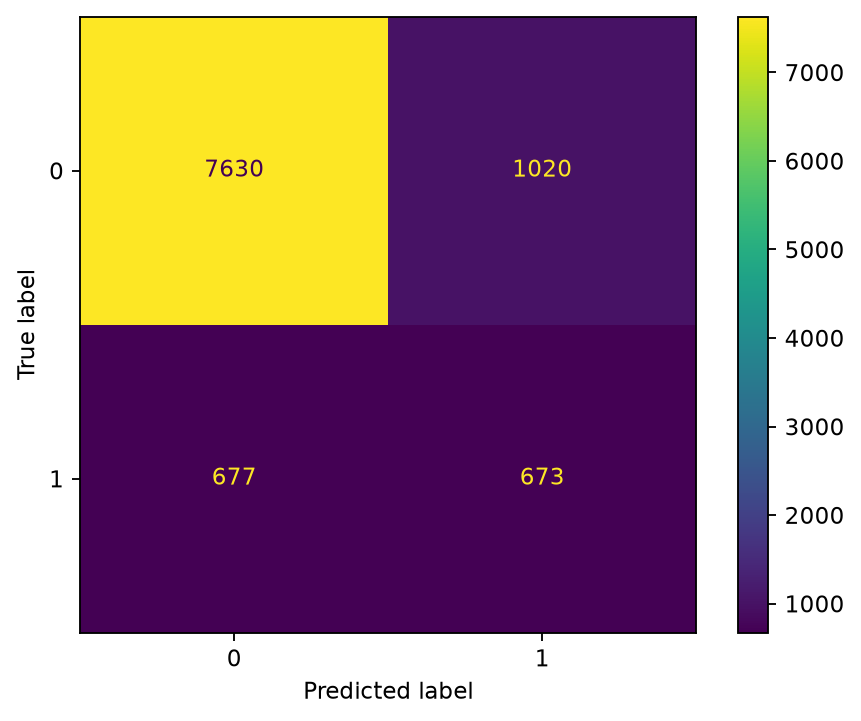

In [330]:
ConfusionMatrixDisplay.from_estimator(tuned_vc, X_test, y_test)

In [331]:
y_pred_train, y_pred_train_proba, y_test_pred, y_test_pred_proba = get_predictions(tuned_vc, X_train, X_test)
print(calculate_metrics(y_test, y_test_pred, y_test_pred_proba, y_train, y_pred_train, y_pred_train_proba))

shape: (6, 3)
┌───────────┬───────┬───────┐
│ Metrics   ┆ Train ┆ Test  │
│ ---       ┆ ---   ┆ ---   │
│ str       ┆ f64   ┆ f64   │
╞═══════════╪═══════╪═══════╡
│ Accuracy  ┆ 0.834 ┆ 0.83  │
│ Precision ┆ 0.426 ┆ 0.398 │
│ Recall    ┆ 0.525 ┆ 0.499 │
│ F1-score  ┆ 0.47  ┆ 0.442 │
│ ROC-AUC   ┆ 0.843 ┆ 0.806 │
│ LogLoss   ┆ 0.309 ┆ 0.32  │
└───────────┴───────┴───────┘


In [334]:
print("Best score of LR = ", tuned_lr.estimator_.best_score_.round(3))
print("Best score of kNN = ", tuned_knn.estimator_.best_score_.round(3))
print("Best score of LR + kNN = ", tuned_vc.estimator_.best_score_.round(3))

Best score of LR =  0.806
Best score of kNN =  0.791
Best score of LR + kNN =  0.805


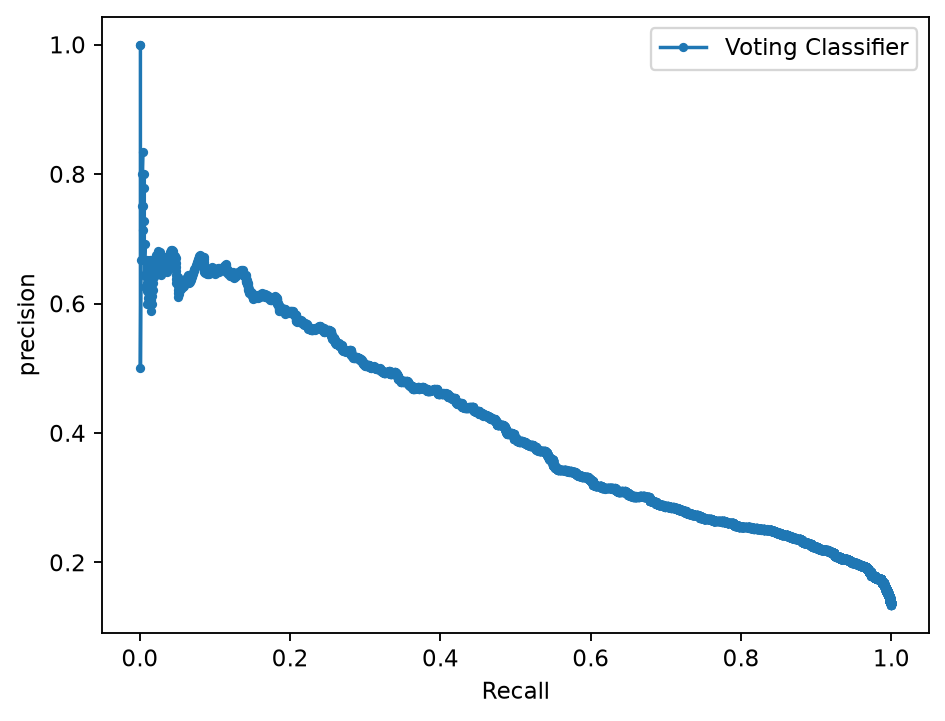

Best treshold 0.243, best F1 score 0.446


In [ ]:
plot_precision_recall_curve(y_test, y_test_pred_proba, 'Voting Classifier')

## LightGBM

### Tuning

In [ ]:
pipe_lightgbm = Pipeline(
    steps=[
        ('features', FeaturesTransform()),
        ('ohe', preprocessor),
        ('lightgbm', LGBMClassifier(objective='binary', random_state=2026, n_jobs=1, verbosity=-1))

    ]

)

param_grid_lightgbm = {
    'lightgbm__n_estimators': [100, 300, 500],
    'lightgbm__max_depth': [4, 5, 6],
    'lightgbm__num_leaves': [15, 31, 63],
    'lightgbm__reg_lambda': [1, 3, 5, 10],
    'lightgbm_learning_rate': [0.1, 0.01]
}

RS_lightgbm = RandomizedSearchCV(estimator=pipe_lightgbm, param_distributions=param_grid_lightgbm, n_iter=50, cv=5, scoring='roc_auc', n_jobs=-1, random_state=2026)
RS_lightgbm.fit(X_train, y_train)

In [45]:
pipe_lightgbm = Pipeline(
    steps=[
        ('features', FeaturesTransform()),
        ('ohe', preprocessor),
        ('lightgbm', LGBMClassifier(objective='binary', random_state=2026, n_jobs=1, verbosity=-1))

    ]

)

param_grid_lightgbm = {
    'lightgbm__n_estimators': [100, 300, 500],
    'lightgbm__max_depth': [4, 5, 6],
    'lightgbm__num_leaves': [15, 31, 63],
    'lightgbm__reg_lambda': [1, 3, 5, 10],
    'lightgbm__learning_rate': [0.1, 0.01]
}

RS_lightgbm = RandomizedSearchCV(estimator=pipe_lightgbm, param_distributions=param_grid_lightgbm, n_iter=50, cv=5, scoring='roc_auc', n_jobs=-1, random_state=2026)
tuned_lightgbm = TunedThresholdClassifierCV(estimator=RS_lightgbm, scoring='f1', cv=5, thresholds=100)
tuned_lightgbm.fit(X_train, y_train)

,"estimator estimator: estimator instanceThe classifier, fitted or not, for which we want to optimizethe decision threshold used during `predict`.",RandomizedSea...ing='roc_auc')
,"scoring scoring: str or callable, default=""balanced_accuracy""The objective metric to be optimized. Can be one of:- str: string associated to a scoring function for binary classification, see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.",'f1'
,"cv cv: int, float, cross-validation generator, iterable or ""prefit"", default=NoneDetermines the cross-validation splitting strategy to train classifier.Possible inputs for cv are:* `None`, to use the default 5-fold stratified K-fold cross validation;* An integer number, to specify the number of folds in a stratified k-fold;* A float number, to specify a single shuffle split. The floating number should be in (0, 1) and represent the size of the validation set;* An object to be used as a cross-validation generator;* An iterable yielding train, test splits;* `""prefit""`, to bypass the cross-validation.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... warning:: Using `cv=""prefit""` and passing the same dataset for fitting `estimator` and tuning the cut-off point is subject to undesired overfitting. You can refer to :ref:`TunedThresholdClassifierCV_no_cv` for an example. This option should only be used when the set used to fit `estimator` is different from the one used to tune the cut-off point (by calling :meth:`TunedThresholdClassifierCV.fit`).",5
,"response_method response_method: {""auto"", ""decision_function"", ""predict_proba""}, default=""auto""Methods by the classifier `estimator` corresponding to thedecision function for which we want to find a threshold. It can be:* if `""auto""`, it will try to invoke, for each classifier, `""predict_proba""` or `""decision_function""` in that order.* otherwise, one of `""predict_proba""` or `""decision_function""`. If the method is not implemented by the classifier, it will raise an error.",'auto'
,"thresholds thresholds: int or array-like, default=100The number of decision threshold to use when discretizing the output of theclassifier `method`. Pass an array-like to manually specify the thresholdsto use.",100
,"refit refit: bool, default=TrueWhether or not to refit the classifier on the entire training set oncethe decision threshold has been found.Note that forcing `refit=False` on cross-validation having morethan a single split will raise an error. Similarly, `refit=True` inconjunction with `cv=""prefit""` will raise an error.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. When `cv` represents across-validation strategy, the fitting and scoring on each data splitis done in parallel. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of cross-validation when `cv` is a float.See :term:`Glossary <random_state>`.",None
,"store_cv_results store_cv_results: bool, default=FalseWhether to store all scores and thresholds computed during the cross-validationprocess.",False
Name,Type,Value
"best_score_ best_score_: float or NoneThe optimal score of the objective metric, evaluated at `best_threshold_`.",float64,0.4469


### Metrics

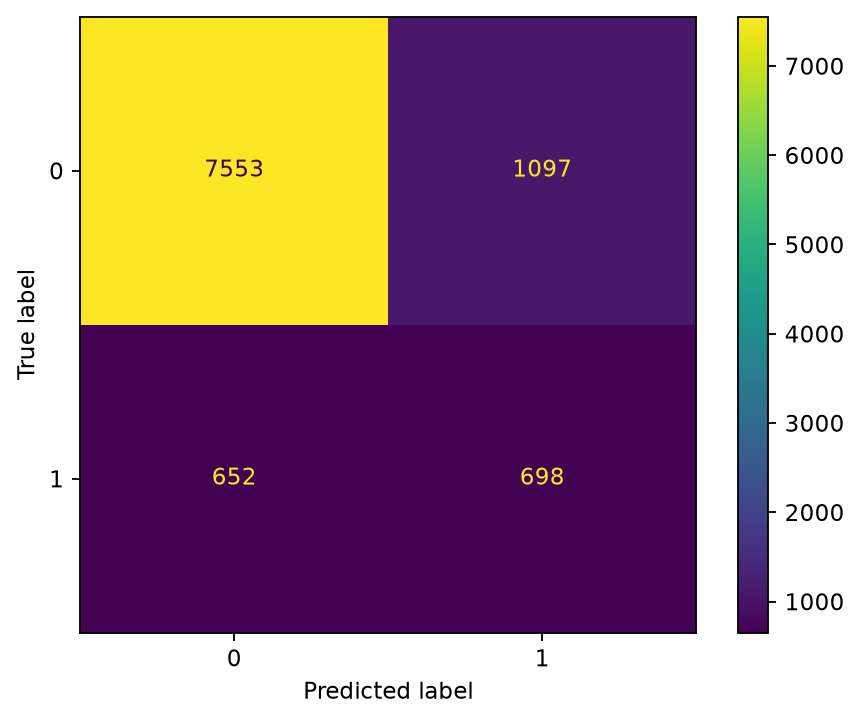

In [47]:
ConfusionMatrixDisplay.from_estimator(tuned_lightgbm, X_test, y_test)
y_pred_train, y_pred_train_proba, y_test_pred, y_test_pred_proba = get_predictions(tuned_lightgbm, X_train, X_test)

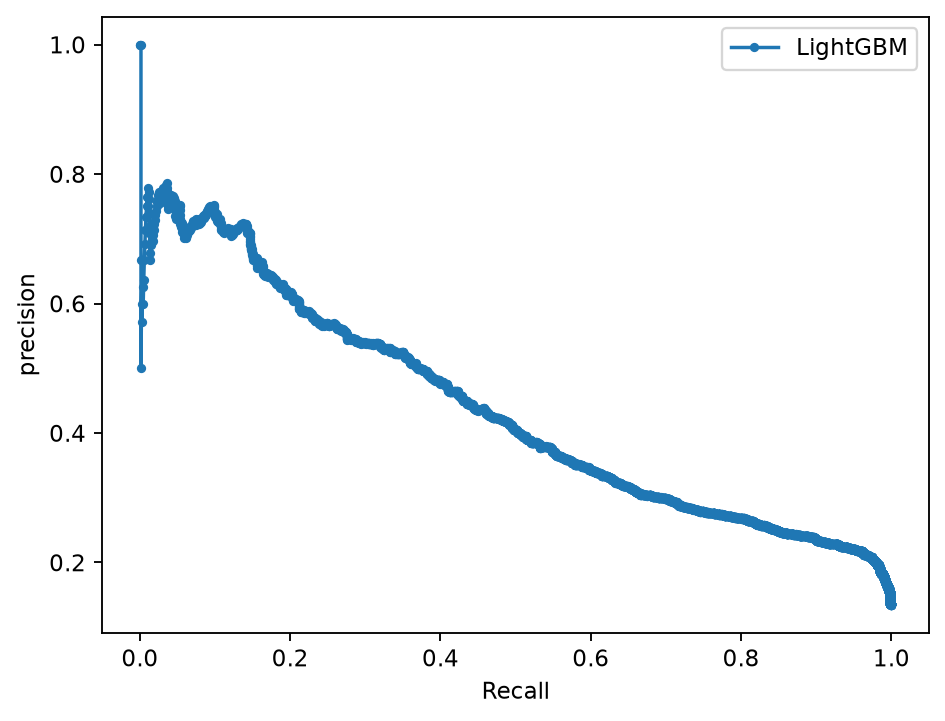

Best treshold 0.234, best F1 score 0.451


In [48]:
plot_precision_recall_curve(y_test, y_test_pred_proba, 'LightGBM')

In [49]:
print(calculate_metrics(y_test, y_test_pred, y_test_pred_proba, y_train, y_pred_train, y_pred_train_proba))

shape: (6, 3)
┌───────────┬───────┬───────┐
│ Metrics   ┆ Train ┆ Test  │
│ ---       ┆ ---   ┆ ---   │
│ str       ┆ f64   ┆ f64   │
╞═══════════╪═══════╪═══════╡
│ Accuracy  ┆ 0.829 ┆ 0.825 │
│ Precision ┆ 0.415 ┆ 0.389 │
│ Recall    ┆ 0.539 ┆ 0.517 │
│ F1-score  ┆ 0.469 ┆ 0.444 │
│ ROC-AUC   ┆ 0.838 ┆ 0.819 │
│ LogLoss   ┆ 0.306 ┆ 0.31  │
└───────────┴───────┴───────┘


### Interpretation of contributing features

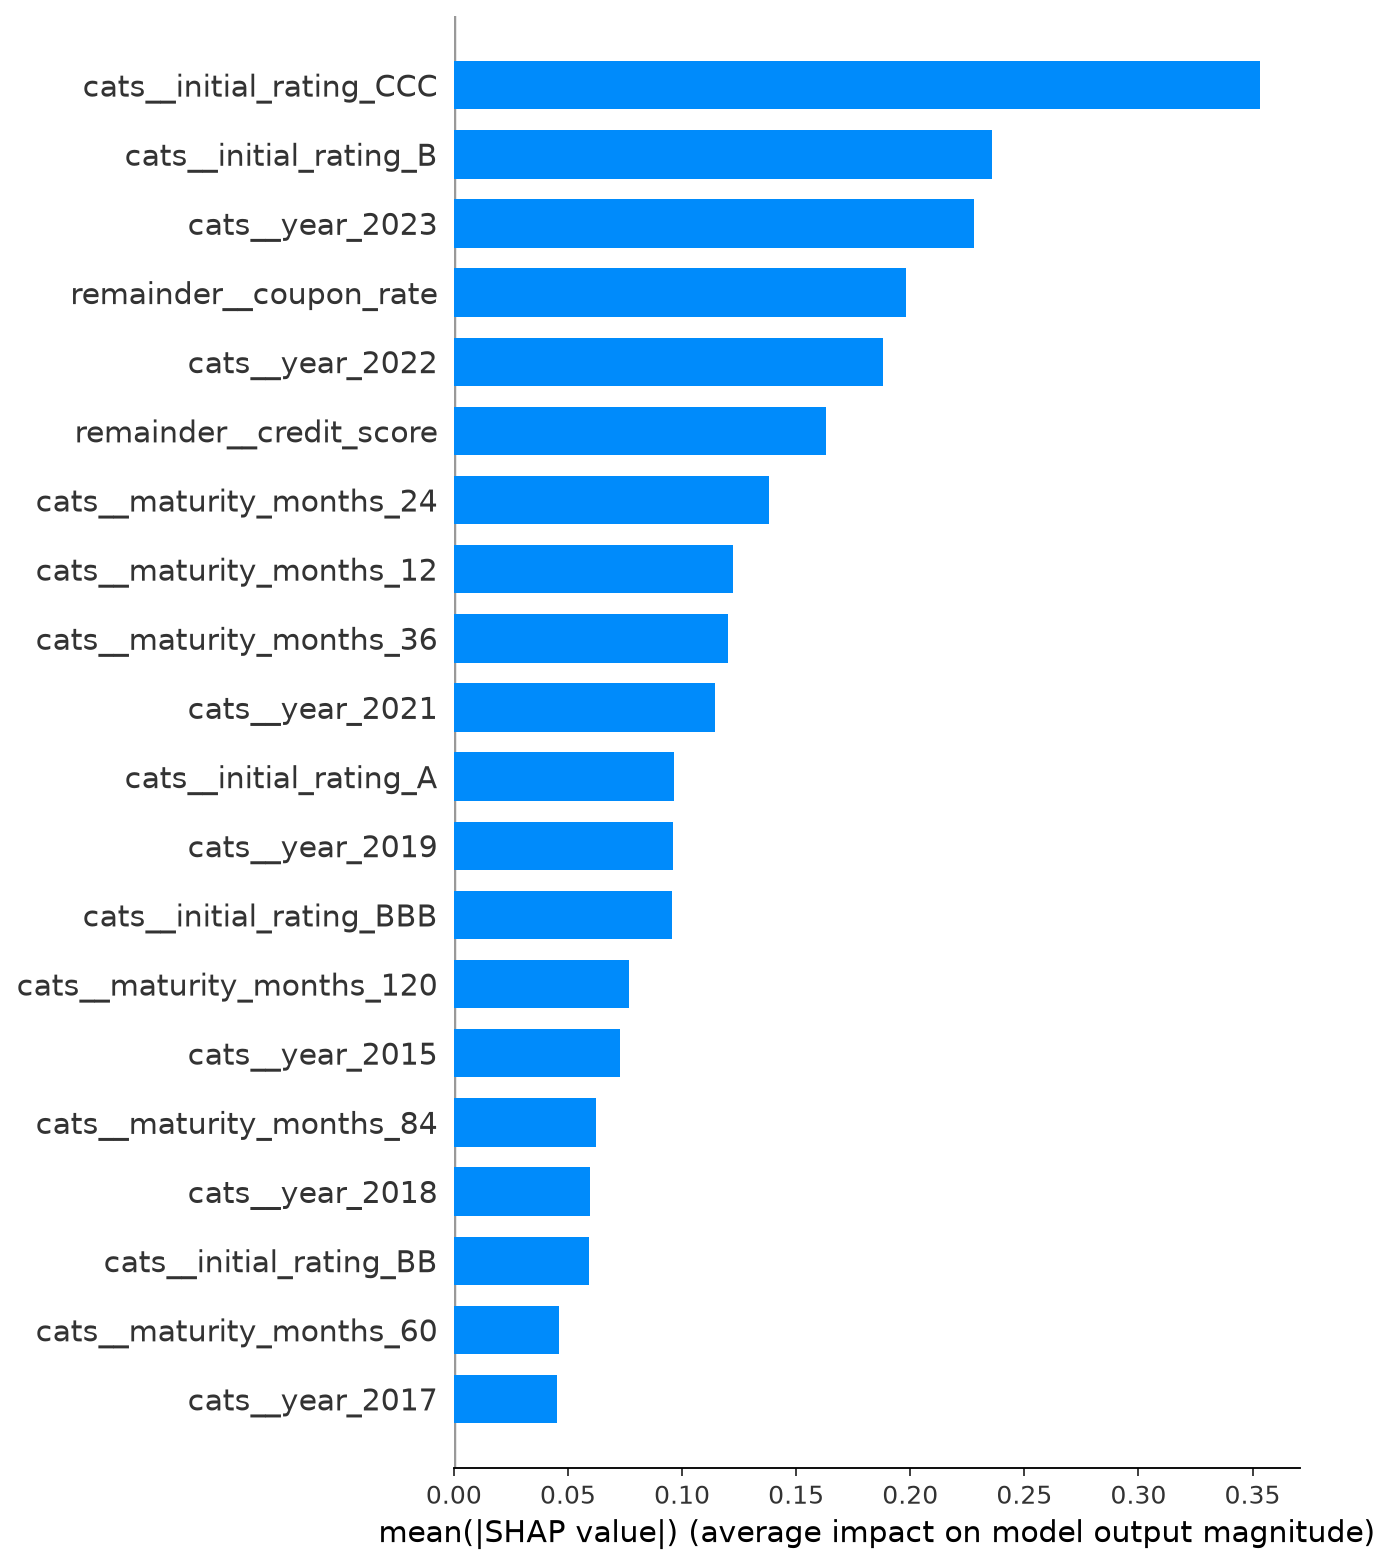

In [51]:
import shap

model = tuned_lightgbm.estimator_.best_estimator_.named_steps['lightgbm']
X_test_transformed = tuned_lightgbm.estimator_.best_estimator_[:-1].transform(X_test)

explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test_transformed)
shap_values.feature_names = tuned_lightgbm.estimator_.best_estimator_.named_steps['ohe'].get_feature_names_out()

shap.summary_plot(shap_values, X_test_transformed, plot_type="bar")

## CatBoost

### Tuning

In [73]:
from sklearn import set_config
set_config(enable_metadata_routing=True)

pipe_сatboost = Pipeline(
    steps=[
        ('features', FeaturesTransform()),
        ('catboost',  CatBoostClassifier(verbose=False, random_seed=2026, cat_features=tuple(cats)))
    ]
)

param_grid_catboost = {
    'catboost__iterations': [500, 1000],
    'catboost__depth': [4, 5, 6],
    'catboost__l2_leaf_reg': [1, 3, 5, 10]
}

RS_catboost = RandomizedSearchCV(estimator=pipe_сatboost, param_distributions=param_grid_catboost, n_iter=50, cv=5, scoring='roc_auc', n_jobs=-1, random_state=2026)
RS_catboost.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...bose=False))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'catboost__depth': [4, 5, ...], 'catboost__iterations': [500, 1000], 'catboost__l2_leaf_reg': [1, 3, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",50
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",2026
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric eval

In [84]:
RS_catboost.best_estimator_

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('catboost', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"


### Metrics

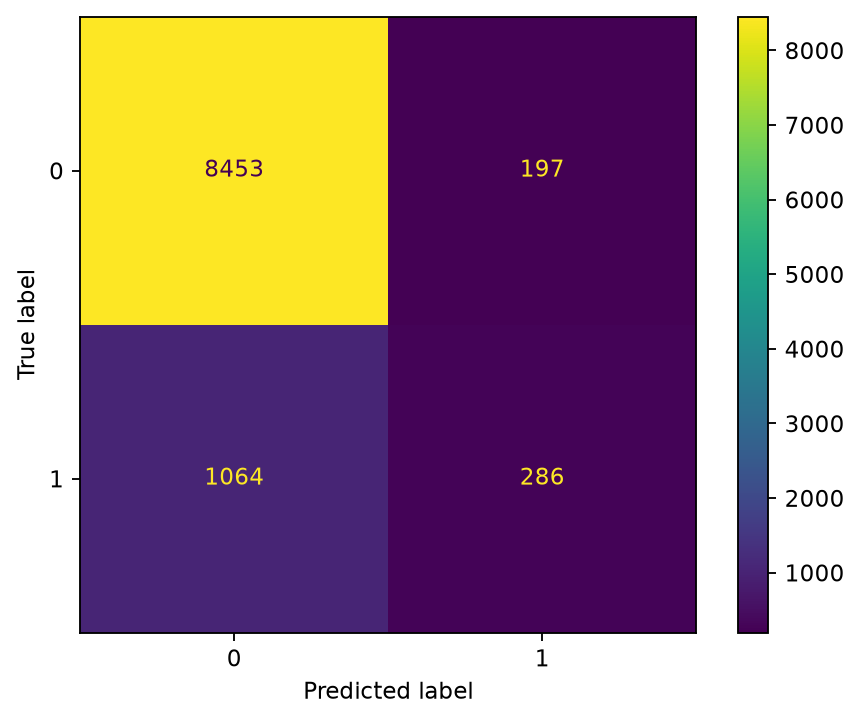

In [74]:
ConfusionMatrixDisplay.from_estimator(RS_catboost, X_test, y_test)
y_pred_train, y_pred_train_proba, y_test_pred, y_test_pred_proba = get_predictions(RS_catboost, X_train, X_test)

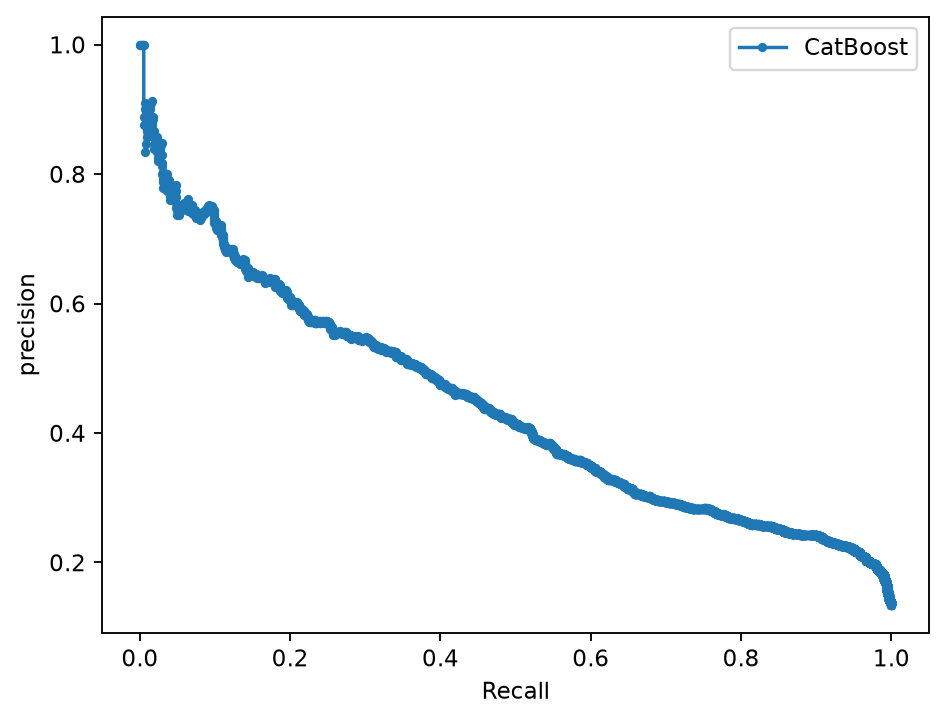

Best treshold 0.218, best F1 score 0.456


In [75]:
plot_precision_recall_curve(y_test, y_test_pred_proba, 'CatBoost')

In [82]:
y_pred_train_proba = RS_catboost.predict_proba(X_train)[:, 1] 
y_pred_train = (y_pred_train_proba >= 0.218).astype(int)
y_test_pred_proba = RS_catboost.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_pred_proba >= 0.218).astype(int)

In [83]:
print(calculate_metrics(y_test, y_test_pred, y_test_pred_proba, y_train, y_pred_train, y_pred_train_proba))

shape: (6, 3)
┌───────────┬───────┬───────┐
│ Metrics   ┆ Train ┆ Test  │
│ ---       ┆ ---   ┆ ---   │
│ str       ┆ f64   ┆ f64   │
╞═══════════╪═══════╪═══════╡
│ Accuracy  ┆ 0.832 ┆ 0.834 │
│ Precision ┆ 0.419 ┆ 0.408 │
│ Recall    ┆ 0.52  ┆ 0.515 │
│ F1-score  ┆ 0.464 ┆ 0.455 │
│ ROC-AUC   ┆ 0.831 ┆ 0.819 │
│ LogLoss   ┆ 0.307 ┆ 0.308 │
└───────────┴───────┴───────┘


# Conclusion

Summary of metrics estimated on train and test samples (train and test sets metrics are separated with /):

| **Model** | **Threshold** | **ROC-AUC** | **Accuracy** | **Precision** | **Recall** | **F1-score** | **LogLoss** |
|---|---:|---:|---:|---:|---:|---:|---:|
| Logistic Regression | 0.216 | 0.807 / 0.807 | 0.833 / 0.834 | 0.417 / 0.405 | 0.485 / 0.481 | 0.449 / 0.440 | 0.326 / 0.321 |
| Decision Tree | 0.212 | 0.779 / 0.750 | 0.819 / 0.814 | 0.384 / 0.352 | 0.478 / 0.453 | 0.425 / 0.397 | 0.332 / 0.421 |
| K-Nearest Neighbors | 0.176 | 0.809 / 0.797 | 0.833 / 0.830 | 0.416 / 0.390 | 0.479 / 0.468 | 0.445 / 0.426 | 0.344 / 0.340 |
| Voting Classifier | 0.243 | 0.843 / 0.806 | 0.834 / 0.830 | 0.426 / 0.398 | 0.525 / 0.499 | 0.470 / 0.442 | 0.309 / 0.320 |
| LightGBM | 0.234 | 0.838 / 0.819 | 0.829 / 0.825 | 0.415 / 0.389 | 0.539 / 0.517 | 0.469 / 0.444 | 0.306 / 0.310 |
| CatBoost | 0.218 | 0.831 / 0.819 | 0.832 / 0.834 | 0.419 / 0.408 | 0.520 / 0.515 | 0.464 / 0.455 | 0.307 / 0.308 |

As shown in the table above, the Gradient Boosting (GB) models demonstrate the highest ROC-AUC scores on the validation set among other models. Decision Tree underperforms relative to Logistic Regression and kNN, Logistic Regression performs on par with GB, it also demonstrated demonstrated nearly identical ROC-AUC scores on the training and test sets. 

Ansembling Logistic Regression with kNN within voting algorithm achieves slightly underperforms the individual constituents algorithms on test ROC-AUC scores, however its F1 shows improvement in loans classifications. CatBoost and LightGBM yield highest test ROC-AUC scores, and CatBoost F1 score exceeds LightGBM. This difference in detection performance can be explained with preponderance of categorical features in the dataset and their optimized processing in CatBoost library. However, LightGBM is noticably faster.

The summary table also contains optimal classification tresholds maximizing F1 delivered from cross-validation for each evaluated model.